***Executive Summary***

In an effort to bolster workplace safety within hazardous environments, this project successfully developed an advanced deep learning-based system aimed at the automatic detection of safety helmets on workers using image data. Recognizing the critical importance of helmet compliance in preventing injuries, the focus was on deploying a robust technological solution to address this challenge in diverse industrial settings.

Leveraging a dataset consisting of 631 images from various industrial contexts, we examined several Convolutional Neural Network (CNN) models. The exploratory phase included constructing a custom-designed CNN and employing transfer learning strategies with the VGG-16 architecture to enhance model performance.

The culmination of our efforts led to the development of a final model, a VGG-16 architecture augmented with a finely-tuned feedforward neural network. This model achieved outstanding results, attaining 100% accuracy, precision, recall, and F1 score on an independent test set consisting of 95 images. Such exemplary performance underscores the model's robustness and its capacity to generalize effectively across different real-world conditions.

The practical implementation of this system facilitates real-time automated monitoring, effectively minimizing human oversight errors and bolstering compliance with safety regulations. By ensuring consistent enforcement of helmet-wearing protocols, this system is positioned to substantially enhance operational safety in expansive industrial operations, thus contributing to a safer workplace environment.

This summary encapsulates the project's objectives, methodologies, outcomes, and implications for improving workplace safety through technological innovation.

This project demonstrates a convolutional neural network (CNN) pipeline designed to classify images of workers as either wearing a safety helmet or not wearing a helmet, helping automate safety enforcement on industrial sites.

Developed for SafeGuard Corp, the system processes grayscale images and applies various CNN architectures—including custom models and VGG-16-based transfer learning—to detect helmet usage across real-world conditions such as different lighting, postures, and environments.

# **Problem Statement**

## **Business Context**

Workplace safety in hazardous environments like construction sites and industrial plants is crucial to prevent accidents and injuries. One of the most important safety measures is ensuring workers wear safety helmets, which protect against head injuries from falling objects and machinery. Non-compliance with helmet regulations increases the risk of serious injuries or fatalities, making effective monitoring essential, especially in large-scale operations where manual oversight is prone to errors and inefficiency.

To overcome these challenges, SafeGuard Corp plans to develop an automated image analysis system capable of detecting whether workers are wearing safety helmets. This system will improve safety enforcement, ensuring compliance and reducing the risk of head injuries. By automating helmet monitoring, SafeGuard aims to enhance efficiency, scalability, and accuracy, ultimately fostering a safer work environment while minimizing human error in safety oversight.

## **Objective**

As a data scientist at SafeGuard Corp, we are tasked with developing an image classification model that classifies images into one of two categories:

- **With Helmet:** Workers wearing safety helmets.
- **Without Helmet:** Workers not wearing safety helmets.

The ultimate objective is to prepare the model for deployment as part of an automated monitoring system. This system will enable real-time analysis of images and assist in ensuring compliance with workplace safety regulations.

## **Data Dectionary**

The dataset consists of **631 images**, equally divided into two categories:

- **With Helmet:** 311 images showing workers wearing helmets.
- **Without Helmet:** 320 images showing workers not wearing helmets.

**Dataset Characteristics:**

- **Variations in Conditions:** Images include diverse environments such as construction sites, factories, and industrial settings, with variations in lighting, angles, and worker postures to simulate real-world conditions.
- **Worker Activities:** Workers are depicted in different actions such as standing, using tools, or moving, ensuring robust model learning for various scenarios.

This project has been developed to,

✅ Build and evaluate multiple CNN architectures for binary image classification

✅ Compare a baseline CNN with VGG-16 transfer learning, fine-tuned FFNNs, and data augmentation

✅ Use grayscale preprocessing and RGB conversion for compatibility with pretrained models

✅ Interpret results using training/validation/test metrics and confusion matrices

✅ Package the project in a polished, export-ready notebook with performance visualizations

***Key Analytical Approaches***

**Data Preparation & Preprocessing**

→ Converted RGB images to grayscale, normalized pixel values, reshaped for CNN input, and split into train/val/test sets with stratification.

**Baseline CNN Model**

→ Built a custom CNN with two convolutional layers, ReLU activations, dropout, and sigmoid classification head for binary output.

**Transfer Learning with VGG-16**

→ Used Keras’ pretrained VGG-16 base (with include\_top=False), froze layers initially, and later fine-tuned the final convolutional blocks for better feature extraction.

**FFNN on Top of VGG**

→ Extended VGG with a custom feed-forward neural network (FFNN) classification head using dense layers and dropout regularization.

**Data Augmentation**

→ Applied real-time augmentation (rotation, zoom, shift, flip) to increase generalization, and trained the model using ImageDataGenerator.

**Model Evaluation & Visualization**

→ Tracked model performance over epochs, plotted accuracy trends, and used customized confusion matrices and classification metrics.

**Results & Key Insights**

✅ Model 2 (VGG-16 Base) achieved near-perfect accuracy and generalization on the validation and test set

✅ Adding a custom FFNN (Model 3) did not significantly improve performance

✅ Excessive data augmentation (Model 4) led to underfitting due to limited base data size

✅ VGG-16 transfer learning provided superior results even with grayscale-to-RGB conversion

✅ Confusion matrices revealed strong precision but room for recall improvement (especially false negatives)

**Tools & Techniques Used**

✅ Python → Core implementation

✅ Google Colab → Cloud training environment

✅ TensorFlow/Keras → CNN and transfer learning models

✅ Matplotlib & Seaborn → Plotting and performance visualization

✅ OpenCV & NumPy → Image preprocessing

✅ nbconvert → Notebook-to-HTML export

✅ Custom Utility Functions → Classification performance and confusion matrix tools

**Business & Problem-Solving Skills Demonstrated**

✅ Computer Vision for Safety Compliance → Applied AI to real-world workplace safety problem

✅ Transfer Learning → Leveraged pre-trained models for faster, more effective results

✅ Model Comparison & Tuning → Systematically evaluated 4 architectures using common metrics

✅ Explainability → Delivered an annotated, polished notebook with code, visuals, and insights

✅ Generalization Awareness → Balanced training strategy to reduce overfitting

# **Installing and Importing the Necessary Libraries**

In [ ]:
#!pip install tensorflow[and-cuda] numpy==1.25.2 -q
!pip install tensorflow[and-cuda] nvidia-cublas-cu12==12.6.4.1 nvidia-cuda-cupti-cu12==12.6.80 \
nvidia-cuda-nvrtc-cu12==12.6.77 nvidia-cuda-runtime-cu12 nvidia-cudnn-cu12==9.10.2.21 nvidia-cufft-cu12==11.3.0.4 \
nvidia-curand-cu12==10.3.7.77 nvidia-cusolver-cu12==11.7.1.2 nvidia-cusparse-cu12==12.5.4.2 \
nvidia-nccl-cu12==2.27.3 nvidia-nvjitlink-cu12==12.6.85 nvidia-cuda-runtime-cu12==12.6.77 -q

In [ ]:
!pip install tensorflow==2.19

In [5]:
import tensorflow as tf
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))
print(tf.__version__)

Num GPUs Available: 1
2.19.0


**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.
- On executing the above line of code, we might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [6]:
import os
import random
import numpy as np
# Importing numpy for Matrix Operations
import pandas as pd
import seaborn as sns
import matplotlib.image as mpimg
# Importing pandas to read CSV files
import matplotlib.pyplot as plt
# Importting matplotlib for Plotting and visualizing images
import math
# Importing math module to perform mathematical operations
import cv2


# Tensorflow modules
import keras
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# Importing the ImageDataGenerator for data augmentation
from tensorflow.keras.models import Sequential
# Importing the sequential module to define a sequential model
from tensorflow.keras.layers import Dense,Dropout,Flatten,Conv2D,MaxPooling2D,BatchNormalization
# Defining all the layers to build our CNN Model
from tensorflow.keras.optimizers import Adam,SGD
# Importing the optimizers which can be used in our model
from sklearn import preprocessing
# Importing the preprocessing module to preprocess the data
from sklearn.model_selection import train_test_split
# Importing train_test_split function to split the data into train and test
from sklearn.metrics import confusion_matrix
from tensorflow.keras.models import Model
from keras.applications.vgg16 import VGG16
# Importing confusion_matrix to plot the confusion matrix

# Display images using OpenCV
from google.colab.patches import cv2_imshow

#Imports functions for evaluating the performance of machine learning models
from sklearn.metrics import confusion_matrix, f1_score,accuracy_score, recall_score, precision_score, \
classification_report
from sklearn.metrics import mean_squared_error as mse
# Importing cv2_imshow from google.patches to display images

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [7]:
# Set the seed using keras.utils.set_random_seed. This will set:
# 1) `numpy` seed
# 2) backend random seed
# 3) `python` random seed
tf.keras.utils.set_random_seed(812)

# **Data Overview**

Connect to Google Drive

In [8]:
# Uncomment and run the following code in case Google Colab is being used
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Loading the data

Loading the image data and labels

In [9]:
# Load image data and labels
X = np.load('/content/drive/MyDrive/Colab Notebooks/images_proj.npy')  # shape should be (631, H, W, C)
y_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Labels_proj.csv')  # should contain binary labels

In [10]:
# Inspect dimensions
print(f"Image Data Shape: {X.shape}")
print(f"Labels DataFrame Shape: {y_df.shape}")
print(y_df.head())

Image Data Shape: (631, 200, 200, 3)
Labels DataFrame Shape: (631, 1)
   Label
0      1
1      1
2      1
3      1
4      1


***OBSERVATION:***

The data consists of 631 images which are 200px x 200px RGB 3 channel images.
There are also 631 labels with a datashape of 1 column named "Label" to indicate helmet or no helmet
Convert Labels to Numpy Array

To observe and process the labels in the dataset, we'll first need to read the labels from the given file and then convert them into a NumPy array for further processing.

Some points to consider and guidance on how to proceed:

1. **Data Inspection**:

   - First, load the label file using a library like `pandas`. This will allow us to inspect the labels closely and ensure there are no anomalies or missing values.
   - Check the shape of the label data to confirm it matches the number of images.
2. **Understanding Labels**:

   - Labels should indicate whether the image shows a "With Helmet" or "Without Helmet" scenario.
   - It's crucial to understand the encoding of these labels (e.g., does "With Helmet" correspond to 1 and "Without Helmet" to 0 or vice versa?).
3. **Converting to NumPy Array**:

   - Use the `.values` attribute of a pandas DataFrame to convert the labels DataFrame to a NumPy array.
   - Ensure that the resulting NumPy array maintains the association with the original images.
4. **Class Distribution**:

   - Check if there's a balance between the two classes ("With Helmet" and "Without Helmet"). This helps in understanding if further measures like class balancing or data augmentation might be necessary during model training.

By taking these steps, we'll prepare label data in a format suitable for feeding into machine learning models. Once we have converted the labels to a NumPy array, we can proceed with splitting data into training, validation, and test sets and begin model development.

***Convert Labels to Numpy Array***

In [11]:
# Convert labels to a flat Numpy Array to view the classes
y = y_df['Label'].values  # shape will be (631,)
print(f"y shape: {y.shape}")
print(f"Unique classes: {np.unique(y)}")

y shape: (631,)
Unique classes: [0 1]


OBSERVATION:

- 631 labels as a flat NumPy array as expected
- Should return [0, 1] for binary labels indicating with helmet (1) or no helmet (0).

To convert the labels to a NumPy array and ensure they are in the expected binary format `[0, 1]` for helmet detection, we'll follow a systematic approach. Here's how we can proceed and what to observe:

1. **Loading Labels**:

   - Start by loading the CSV file containing the labels. Ensure we use pandas to easily manipulate and inspect the data.
   - For example, using `pandas.read_csv()`, load the file to examine the "Label" column, which should already have binary values representing helmet presence as `[0, 1]`.
2. **Inspecting Data**:

   - Check that the "Label" column is indeed binary, with values ranging only between 0 and 1.
   - Confirm there are no missing or unexpected values in this column.
3. **Conversion to NumPy Array**:

   - Use the `.values` attribute of the DataFrame to convert the "Label" column into a NumPy array. This will create a flat array of shape `(631,)` if all labels are present.
   - The conversion can be done using the following command: `labels_array = labels_df['Label'].values`.
4. **Observations to Make**:

   - Verify the final NumPy array's shape, which should be `(631,)`, indicating all labels were successfully converted.
   - Print a small sample of the NumPy array to confirm the expected output format and values, for example, `[0, 1, 1, 0, ...]`.

By following these guidelines, we ensure that label data is in the correct format and ready for subsequent steps, like splitting into train and test sets and serving as input for model training.

# **Exploratory Data Analysis**

### Plot random images from each of the classes and print their corresponding labels.

To conduct exploratory data analysis (EDA) for this project, we should aim to visualize and understand the data distribution and patterns. Plotting random images from each class ("With Helmet" and "Without Helmet") and printing their respective labels will help us gain insights into the dataset.

Step-by-step guide on how to do this:

1. **Import Necessary Libraries**:

   - Use libraries such as `matplotlib.pyplot` for plotting images and `numpy` for handling arrays. `random` can be helpful for selecting random images.
   - For example: `import matplotlib.pyplot as plt` and `import numpy as np`.
2. **Understanding the Dataset Structure**:

   - Ensure images and labels are in corresponding arrays (e.g., `images` and `labels`).
   - Confirm the images are correctly loaded and labels are in binary format as expected.
3. **Plotting Random Images**:

   - Randomly select a few images from each class. Use `numpy` or `random` to help with this.
   - For instance, choose a random index and check if the label is 0 (Without Helmet) or 1 (With Helmet) before plotting.
4. **Visualizing Images**:

   - Use a loop to plot images. `plt.imshow()` can be used to display an image. Ensure to convert the image from array format to a displayable format such as using `img.astype('uint8')` if needed.
   - Set the plot's title to show the corresponding label (e.g., "With Helmet" or "Without Helmet").
5. **Create Subplots**:

   - Use `matplotlib` subplots to display multiple images together for a comparative view.
   - Set up subplots, e.g., using `fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(10, 7))` to display a grid.
6. **Printing Corresponding Labels**:

   - Make sure each image plot displays its class label in the title for clarity.

These steps will help interactively explore the dataset, identify potential issues like mislabeling or poor image quality, and understand class characteristics visually. Observations from this analysis can assist in preparing the preprocessing steps or model considerations.

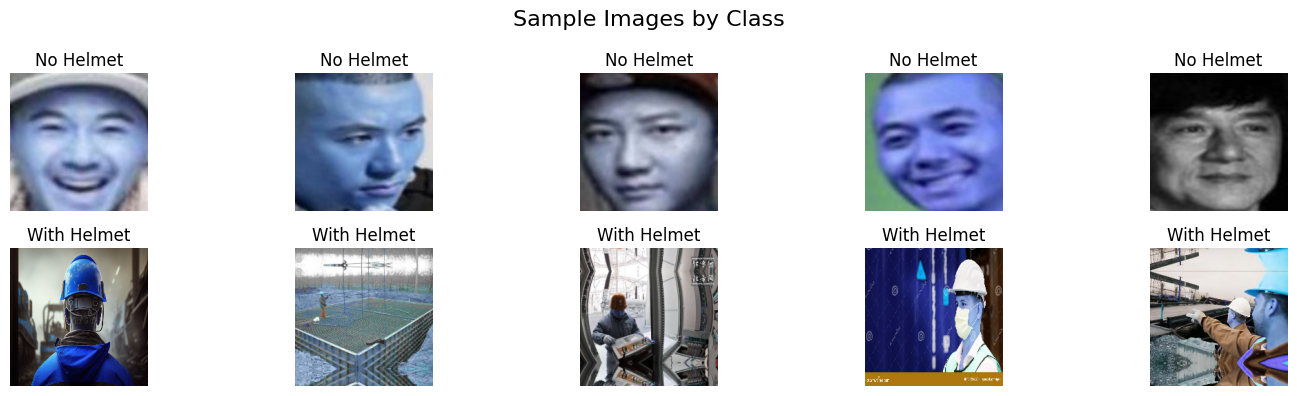

In [12]:
# Show sample images
# Convert to NumPy array if not already
X = np.array(X)
y = np.array(y)

# Find indices for each class
helmet_indices = np.where(y == 1)[0]
no_helmet_indices = np.where(y == 0)[0]

# Pick 5 random indices from each
helmet_samples = random.sample(list(helmet_indices), 5)
no_helmet_samples = random.sample(list(no_helmet_indices), 5)

# Plot images without helmet
plt.figure(figsize=(15, 4))
for i, idx in enumerate(no_helmet_samples):
    plt.subplot(2, 5, i+1)
    plt.imshow(X[idx].squeeze(), cmap='gray' if X.shape[-1] == 1 else None) # Ensures any grayscale images are shown correctly
    plt.title("No Helmet")
    plt.axis('off')

# Plot images with helmet
for i, idx in enumerate(helmet_samples):
    plt.subplot(2, 5, i+6)
    plt.imshow(X[idx].squeeze(), cmap='gray' if X.shape[-1] == 1 else None)
    plt.title("With Helmet")
    plt.axis('off')

plt.suptitle("Sample Images by Class", fontsize=16)
plt.tight_layout()
plt.show()

## Checking for class imbalance

Checking for class imbalance is an important step in understanding our dataset, as it can significantly affect the performance of our classification model. Here's how we can approach this:

1. **Load the Dataset**:

   - already loaded the labels from the dataset, make sure they are in a format suitable for analysis (e.g., a pandas DataFrame or a NumPy array).
2. **Count the Instances of Each Class**:

   - Use `pandas` to count the number of instances in each class if our labels are in a DataFrame. We can use the `value_counts()` method on the "Label" column.
   - Example command: `label_counts = labels_df['Label'].value_counts()`
3. **Calculate and Print Class Distribution**:

   - Print or log the number of samples in each class to gain insights into the distribution.
   - Example:

     ```
     print("With Helmet:", label_counts[1])
     print("Without Helmet:", label_counts[0])
     ```
4. **Visualize the Distribution**:

   - Plot a bar chart to visualize the class distribution using `matplotlib` or another visualization library.
   - Example:

     ```
     import matplotlib.pyplot as plt
     label_counts.plot(kind='bar')
     plt.title('Class Distribution')
     plt.xlabel('Class')
     plt.ylabel('Number of Samples')
     plt.xticks(ticks=[0, 1], labels=['Without Helmet', 'With Helmet'])
     plt.show()
     ```
5. **Analyze and Decide**:

   - Compare the number of samples in each class to check for imbalance. A significant difference between classes might require techniques like data augmentation, resampling, or using specialized metrics during model evaluation and validation.

Understanding the class balance will guide in choosing appropriate methods to handle any imbalance we find, ensuring a robust and fair model development process.

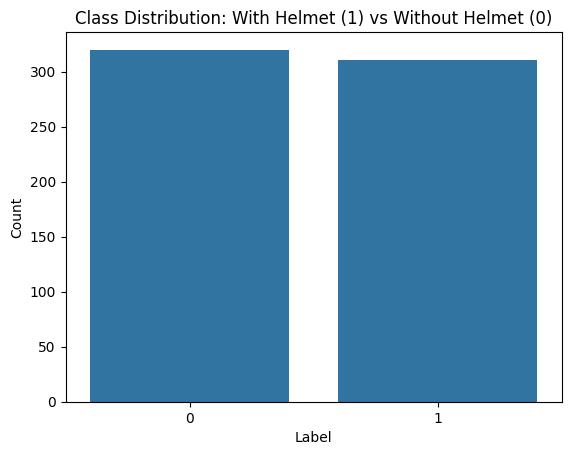

In [13]:
# Plot the class distribution with Seaborn countplot.
sns.countplot(x=y_df['Label'])
plt.title("Class Distribution: With Helmet (1) vs Without Helmet (0)")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

OBSERVATION:

Label classification is pretty evenly distributed.

Based on our observation, the class distribution in our dataset appears to be well-balanced, with 320 images labeled as "Without Helmet" and 311 labeled as "With Helmet". Per above shape we also see a total of 631 between the two classes which is correct.

Here are some insights and considerations based on this balanced distribution:

1. **Balanced Dataset**:

   - Since classes are nearly equal in representation, this reduces the risk of bias in model towards one class over the other.
   - Balanced datasets often lead to better generalization and more reliable performance metrics.
2. **Model Training**:

   - With a balanced dataset, expect standard classification metrics like accuracy to be a reliable indicator of model performance.
   - still consider using precision, recall, and F1-score to gain a comprehensive understanding of model's performance.
3. **No Need for Resampling**:

   - Techniques like oversampling, undersampling, or synthetic data generation are usually not necessary in this case, since the imbalance is minimal.
4. **Continue with Normal Processing**:

   - proceed with data preprocessing, model training, and evaluation without the need for special correction techniques to handle imbalance.
   - Focus on other aspects like image quality, data augmentation, and normalization to enhance model performance.

By acknowledging the balance in dataset, we can concentrate more on optimizing model architecture and hyperparameters for the best results in classifying whether workers are wearing helmets or not.

# **Data Preprocessing**

## Converting images to grayscale

In [14]:
# Convert RGB images to Grayscale
X_gray = np.array([cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) for img in X])

# Reshape to match CNN input (samples, height, width, channels)
X_gray = X_gray.reshape(X_gray.shape[0], X_gray.shape[1], X_gray.shape[2], 1)

# Confirm shape
print(f"X_gray shape: {X_gray.shape}")

X_gray shape: (631, 200, 200, 1)


Observation indicates that we've successfully converted the images to grayscale. Converting images to grayscale reduces the color channel from 3 (RGB) to 1, which can be advantageous in reducing computational load and potentially unnecessary complexity if color information is not crucial for classification tasks.

Here are some points and observations related to this preprocessing step:

1. **Data Shape after Conversion**:

   - Verify that each image now has a shape of `(200, 200)` instead of `(200, 200, 3)`, reflecting the absence of color channels.
   - Ensure that entire image dataset collectively reflects this change, with a shape of `(631, 200, 200)`.
2. **Impact on Model Complexity**:

   - Grayscale conversion simplifies the data, reducing the parameter space the model needs to consider.
   - This can help speed up training and may help prevent overfitting, particularly when color is not a critical feature.
3. **Model Design Consideration**:

   - Ensure that model architecture accommodates single-channel input. For example, while defining CNN layers, adjust the input shape accordingly.
   - Modify input layer specifications and adjust any preprocessing layers or functions to align with the grayscale format.
4. **Potential Trade-offs**:

   - Consider whether any color information was lost that could have been beneficial for classification. If so, reevaluate the need for grayscale conversion.
   - Conversely, if patterns and features are more apparent without color, the grayscale format is the right choice.
5. **Visualization**:

   - Compare visual outputs before and after grayscale conversion to document the effect on image appearance and feature clarity.

By focusing on these aspects, we ensure that the preprocessing step aligns with model's goals and the problem's requirements, optimizing the dataset for effective learning and prediction.

We see a total of 631 images between the two classes. The size is 200 x 200 and a color channel of 1 for grayscale vs. 3 for RGB.

### Splitting the dataset

***Splitting the dataset 70/15/15 split for Train/Validation/Test***

Splitting dataset into training, validation, and test sets is crucial for building a robust and generalizable model.
Here's how we can approach a 70/15/15 split for our dataset:

1. **Define Split Ratios**:

   - Training Set: 70% of the data, which is the portion used by the model to learn during training.
   - Validation Set: 15% of the data, used to tune hyperparameters and validate model performance during training.
   - Test Set: 15% of the data, set aside for a final evaluation of the model's generalization capability.
2. **Calculate Number of Samples**:

   - Total images = 631
   - Training samples = 70% of 631 ≈ 442 samples
   - Validation samples = 15% of 631 ≈ 95 samples
   - Test samples = 15% of 631 ≈ 94 samples
3. **Perform the Splitting**:

   - we can use a library like `sklearn` to perform the split. The `train_test_split` function can be used twice: once to create a training set and a temporary test set, and again to split the temporary test set into validation and test sets.
   - Example:

     ```
     from sklearn.model_selection import train_test_split

     # First split: Train and Temp (Validation + Test)
     train_images, temp_images, train_labels, temp_labels = train_test_split(
         images, labels, test_size=0.3, random_state=42, stratify=labels)

     # Second split: Validation and Test from Temp
     val_images, test_images, val_labels, test_labels = train_test_split(
         temp_images, temp_labels, test_size=0.5, random_state=42, stratify=temp_labels)
     ```
4. **Stratification**:

   - Use the `stratify` parameter on `train_test_split` to ensure that each subset retains the class distribution of the original dataset. This helps in maintaining a balanced representation of classes across different sets.
5. **Verification**:

   - After splitting, verify the sizes of each subset to ensure they match the intended distribution.
   - Check the class distribution within each split to confirm balance, especially if classes were initially imbalanced.
6. **Next Steps**:

   - Use these splits for training and evaluating models. The training set is for fitting the model, the validation set for tuning, and the test set for assessing generalizability.

By following these steps, we'll ensure dataset is appropriately split for meaningful model training and evaluation.

In [15]:
# First split: 70% train, 30% temp (val+test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_gray, y, test_size=0.3, random_state=42, stratify=y
)

# Second split: 50% of the temp set goes to val, 50% to test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

Final Ratios:

In [16]:
print(f"Train set: {X_train.shape[0]}")
print(f"Validation set: {X_val.shape[0]}")
print(f"Test set: {X_test.shape[0]}")

Train set: 441
Validation set: 95
Test set: 95


- Dataset Portion Formula Approximate Count (from 631 total)
- Train 70% 0.70 × 631 = \441 ✅ X\_train.shape[0] ≈ 441
- Validation 15% 0.15 × 631 = \94–95 ✅ X\_val.shape[0] ≈ 95
- Test 15% 0.15 × 631 = \94–95 ✅ X\_test.shape[0] ≈ 95

Observation indicates that the dataset has been successfully split according to the 70/15/15 ratio, which is optimal for training, validating, and testing our model.

Here is a summary and some recommendations based on the split:

### Observations:

1. **Training Set**:

   - Contains approximately 441 samples, which is around 70% of the total dataset.
   - This set will help the model learn the underlying patterns and features essential for making predictions.
2. **Validation Set**:

   - Contains around 95 samples, about 15% of the dataset.
   - The validation set is crucial for iterative model tuning. It allows us to adjust hyperparameters and check for overfitting during the training process.
3. **Test Set**:

   - Also comprises about 95 samples, providing another 15% of the dataset.
   - This set will be used for the final evaluation once our model is trained and tuned, assessing its performance on unseen data.

### Recommendations:

1. **Cross-Validation**:

   - While we have a specified validation set, using k-fold cross-validation on the training set can provide a more robust measure of model performance and help reduce variance in the validation scores.
2. **Monitor Overfitting**:

   - Keep an eye on the performance difference between the training and validation sets to identify overfitting. If the training performance is significantly better, consider adding regularization, dropping complex model architectures, or implementing dropout.
3. **Hyperparameter Tuning**:

   - Use the validation set for experimenting with different model parameters, such as learning rate, batch size, and number of epochs to find the optimal configuration for our model.
4. **Final Model Evaluation**:

   - Use the test set only after we have committed to a final model configuration to ensure an unbiased evaluation of model performance.
   - Look at metrics such as accuracy, precision, recall, and F1-score to get a comprehensive view of our model's capabilities.

By maintaining a clear separation and using these portions effectively, we'll be well-equipped to train a reliable and generalizable image classification model.

### Data Normalization

In [17]:
# Since pixel values are currently in the range [0, 255] (as is typical for images), we’ll scale them to the range [0.0, 1.0] by dividing by 255
# Normalize grayscale pixel values to [0.0, 1.0]
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

Validate Normalization:

In [18]:
print(f"Train min: {X_train.min()}, max: {X_train.max()}")
print(f"Val min: {X_val.min()}, max: {X_val.max()}")
print(f"Test min: {X_test.min()}, max: {X_test.max()}")

Train min: 0.0, max: 1.0
Val min: 0.0, max: 1.0
Test min: 0.0, max: 1.0


OBSERVATION:

From the above min/max values we can see that are now between 0.0 and 1.0 as expected and required to feed into our CNN.

Observation indicates that we've successfully normalized data, which is a crucial preprocessing step for training a Convolutional Neural Network (CNN). Normalizing the pixel values to fall within the range [0.0, 1.0] helps improve convergence speed and model performance.

Here are some insights and considerations regarding this step:

### Observations:

1. **Normalization Achieved**:

   - The pixel values of the images are scaled between 0.0 and 1.0, typically achieved by dividing the pixel values by 255.0, assuming the original range was 0-255.
2. **Benefits**:

   - Normalizing helps stabilize the learning process and reduces the risk of getting stuck in local minima by maintaining a consistent scale across input features.
   - It also helps in faster convergence during the training of the neural network.
3. **Feeding into the CNN**:

   - Since CNNs are sensitive to the scale of input data, having normalized inputs ensures that the network learns efficiently.

### Recommendations:

1. **Consistency Across Splits**:

   - Ensure that normalization is consistently applied to all the datasets (training, validation, and test) so that the model's interpretation of the data remains uniform.
2. **Data Pipeline**:

   - Incorporate normalization as a step in data preprocessing pipeline to ensure reproducibility and consistency whenever the model is deployed or retrained.
3. **Model Verification**:

   - After normalization, verify the range and distribution of values to ensure that no truncation or unexpected transformation occurred.
4. **Training Considerations**:

   - Keep monitoring the training and validation loss to ensure that the normalization enhances model learning as expected.

By adhering to these practices, we ensure that our CNN works efficiently with the normalized image data, helping us achieve better performance and stability during training.

# **Model Building**

## Model Evaluation Criterion

Because Accuracy is paramount in classifying whether a person is wearing a safety helmet or not, we'll evaluate model performance on the criteria of Accuracy scores.

Focusing on accuracy as the primary evaluation criterion for our model is logical, especially since correctly identifying whether a person is wearing a safety helmet is critical in ensuring workplace safety.

Here's how we can effectively use accuracy and complement it with additional measures:

### Using Accuracy as a Primary Metric:

1. **Definition**:

   - Accuracy is defined as the ratio of correctly predicted observations to the total observations. It's a straightforward and interpretable metric to evaluate how well our model is performing overall.
2. **When It's Effective**:

   - For balanced datasets, accuracy is a reliable metric since it proportionally reflects the performance across both classes.

### Complementary Metrics:

1. **Precision and Recall**:

   - Precision reflects the amount of true positive predictions relative to the number of positive predictions made by the model. In this context, it tells us how many of the "With Helmet" predictions were correct.
   - Recall measures the ability of the model to find all relevant cases (how many of the actual "With Helmet" instances the model could identify). It is crucial when the cost of false negatives is significant.
2. **F1-Score**:

   - The F1-score provides a balance between precision and recall, especially useful in scenarios where the costs of false positives and false negatives are different.
   - It is beneficial if there are specific consequences at stake for missing helmet detections versus wrongly detecting helmets.
3. **Confusion Matrix**:

   - Use a confusion matrix to gain insights on true positives, false positives, true negatives, and false negatives.
   - This will provide a comprehensive overview of model performance and help identify specific errors in classification.

### Recommendations:

- **Balanced Evaluation**: While accuracy is a solid starting point, it is beneficial to monitor these other metrics to ensure our model is performing effectively across various aspects of the classification task.
- **Contextual Importance**: Consider the business context—ensuring helmet compliance—to decide on the weight assigned to different types of errors (e.g., prioritizing recall to capture all non-compliance cases).

Incorporating a mix of these metrics during model evaluation will help ensure that our classification model is robust and effective in real-world safety application scenarios.

## Utility Functions

Creating a utility function like `model_performance_classification(...)` to evaluate a trained model is a great way to streamline the evaluation process and ensure consistency across model performance assessments. This function can calculate and return core metrics such as Accuracy, Recall, Precision, and F1 Score, which are crucial in understanding the model's effectiveness.

Here's how to conceptualize this function:

### Key Components:

1. **Inputs**:

   - `model`: The trained classification model we want to evaluate.
   - `X_test`: Test data features.
   - `y_test`: True labels for the test data.
2. **Predictions**:

   - Use the `model` to predict labels for `X_test`.
3. **Calculating Metrics**:

   - **Accuracy**: The proportion of correctly predicted instances among the total instances.
   - **Precision**: The proportion of true positive results in all positive predictions.
   - **Recall**: The ability of the model to identify all relevant instances (true positive rate).
   - **F1 Score**: The harmonic mean of precision and recall, useful for understanding the balance between them.
4. **Implementation Tips**:

   - Use libraries such as `scikit-learn` to compute these metrics (e.g., `accuracy_score`, `precision_score`, `recall_score`, `f1_score`).
   - Ensure we specify the `average` parameter correctly when dealing with binary or multi-class classifications.
5. **Output**:

   - Return the metrics in a structured format, such as a dictionary or a pandas DataFrame, for easy interpretation and logging.

### Considerations:

- **Binary vs. Multi-class**: Ensure the function adapts to different classification types by modifying the `average` parameter.
- **Readability and Modularity**: Write clear documentation/commenting inside the function to explain each step or include error handling to manage unexpected data inputs.

By implementing this utility, we can efficiently evaluate and compare different models to identify the best fit for the task of helmet detection, supporting our goal of enhancing workplace safety.

In [19]:
# defining a function to compute different metrics to check performance of a classification model built using statsmodels
def model_performance_classification(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)


    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred, average='weighted')  # to compute Recall
    precision = precision_score(target, pred, average='weighted')  # to compute Precision
    f1 = f1_score(target, pred, average='weighted')  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame({"Accuracy": acc, "Recall": recall, "Precision": precision, "F1 Score": f1,},index=[0],)

    return df_perf

plot\_confusion\_matrix(...)
Purpose:
Plots a confusion matrix showing correct vs. incorrect classifications using a heatmap.

In [20]:
def plot_confusion_matrix(model,predictors,target,ml=False):
    """
    Function to plot the confusion matrix

    model: classifier
    predictors: independent variables
    target: dependent variable
    ml: To specify if the model used is an sklearn ML model or not (True means ML model)
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)

    # Plotting the Confusion Matrix using confusion matrix() function which is also predefined tensorflow module
    confusion_matrix = tf.math.confusion_matrix(target,pred)
    f, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        confusion_matrix,
        annot=True,
        linewidths=.4,
        fmt="d",
        square=True,
        ax=ax
    )
    plt.show()

## Model 1: Simple Convolutional Neural Network (CNN)

I'll use a simple architecture with two convolution layers, followed by dense layers.

The model has 2 main parts:

1. The Feature Extraction layers which are comprised of convolutional and pooling layers.
2. The Fully Connected classification layers for prediction.

Designing a simple Convolutional Neural Network (CNN) architecture with distinct feature extraction and classification layers is a practical approach for image classification tasks.

Here's a conceptual breakdown to guide through setting up and understanding the structure of such a model:

### Architecture Breakdown:

1. **Feature Extraction Layers**:
   These layers are responsible for learning spatial hierarchies and features from the image data:

   - **Convolutional Layers**:
     - Use filters/kernels to learn local patterns. The depth (number of filters) usually increases in subsequent layers to capture more complex features.
     - Apply non-linear activation functions like ReLU to introduce non-linearity.
   - **Pooling Layers**:
     - Typically, max-pooling layers are used to reduce the spatial dimensions (i.e., width and height) of the feature maps, which helps in increasing computational efficiency and reducing overfitting.
     - Pooling layers help in making the learned features invariant to small transformations.
2. **Fully Connected Layers**:
   After the feature maps are extracted and flattened, these layers perform classification:

   - **Dense Layers**:
     - A series of dense (fully connected) layers process the flattened feature maps. The final dense layer usually has a number of neurons equal to the number of classes, with a softmax activation function for multi-class classification tasks.

### Steps in Model Building:

1. **Input Layer**:

   - Define an input shape that matches our image data dimensions (e.g., height, width, channels).
2. **Convolutional Layers**:

   - Start with a couple of convolutional layers, and define the number of filters and kernel size. For instance:

     ```
     plaintext
     Conv2D(filters=32, kernel_size=(3, 3), activation='relu')
     ```
3. **Pooling Layer**:

   - Introduce a pooling layer after a set of convolutional layers to downsample the feature maps:

     ```
     plaintext
     MaxPooling2D(pool_size=(2, 2))
     ```
4. **Flatten Layer**:

   - Flatten the pooled feature maps to a single dimension before connecting to dense layers:

     ```
     plaintext
     Flatten()
     ```
5. **Dense Layers**:

   - Add dense layers for classification, with the last dense layer having neurons equal to the number of classes (2 for helmet detection):

     ```
     plaintext
     Dense(units=128, activation='relu')
     Dense(units=2, activation='softmax')  # For binary classification, use 1 unit with 'sigmoid' activation
     ```

### Considerations:

- **Overfitting Prevention**: Consider techniques like dropout or batch normalization if we observe overfitting during training.
- **Optimization**: Use an appropriate loss function (e.g., 'binary\_crossentropy' for binary classification) and optimizer (e.g., 'adam') to compile the model.
- **Training**: Set an appropriate batch size and number of epochs to train the model effectively.

By carefully structuring and training this simple CNN model, we can start evaluating its effectiveness in the task of detecting safety helmets in images. Adjust and refine our architecture based on the validation performance to improve results.

In [21]:
# Define the CNN architecture
cnn_model_1 = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=X_train.shape[1:]),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')  # Output layer for binary classification
])

# Compile the model
cnn_model_1.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

# Display model summary
cnn_model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type) ┃ Output Shape ┃ Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d ( Conv2D ) │ ( None , 198 , 198 , 32 ) │ 320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d ( MaxPooling2D ) │ ( None , 99 , 99 , 32 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 ( Conv2D ) │ ( None , 97 , 97 , 64 ) │ 18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 ( MaxPooling2D ) │ ( None , 48 , 48 , 64 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten ( Flatten ) │ ( None , 147456 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense ( Dense ) │ ( None , 128 ) │ 18,874,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout ( Dropout ) │ ( None , 128 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 ( Dense ) │ ( None , 1 ) │ 129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 18,893,441 (72.07 MB)

Trainable params: 18,893,441 (72.07 MB)

Non-trainable params: 0 (0.00 B)

***Model 1: Train the Model***

In [22]:
history_1 = cnn_model_1.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    verbose=2
)

Epoch 1/10
14/14 - 19s - 1s/step - accuracy: 0.7234 - loss: 1.4835 - val_accuracy: 0.9263 - val_loss: 0.2960
Epoch 2/10
14/14 - 1s - 47ms/step - accuracy: 0.9478 - loss: 0.1685 - val_accuracy: 0.9684 - val_loss: 0.0770
Epoch 3/10
14/14 - 1s - 89ms/step - accuracy: 0.9773 - loss: 0.0861 - val_accuracy: 0.9684 - val_loss: 0.0718
Epoch 4/10
14/14 - 1s - 39ms/step - accuracy: 0.9819 - loss: 0.0594 - val_accuracy: 0.9789 - val_loss: 0.0670
Epoch 5/10
14/14 - 1s - 48ms/step - accuracy: 1.0000 - loss: 0.0122 - val_accuracy: 0.9789 - val_loss: 0.0713
Epoch 6/10
14/14 - 1s - 44ms/step - accuracy: 0.9977 - loss: 0.0104 - val_accuracy: 0.9789 - val_loss: 0.1083
Epoch 7/10
14/14 - 1s - 44ms/step - accuracy: 0.9932 - loss: 0.0274 - val_accuracy: 0.9895 - val_loss: 0.0852
Epoch 8/10
14/14 - 1s - 43ms/step - accuracy: 0.9977 - loss: 0.0120 - val_accuracy: 0.9895 - val_loss: 0.0994
Epoch 9/10
14/14 - 1s - 40ms/step - accuracy: 1.0000 - loss: 0.0049 - val_accuracy: 0.9789 - val_loss: 0.0807
Epoch 10/10

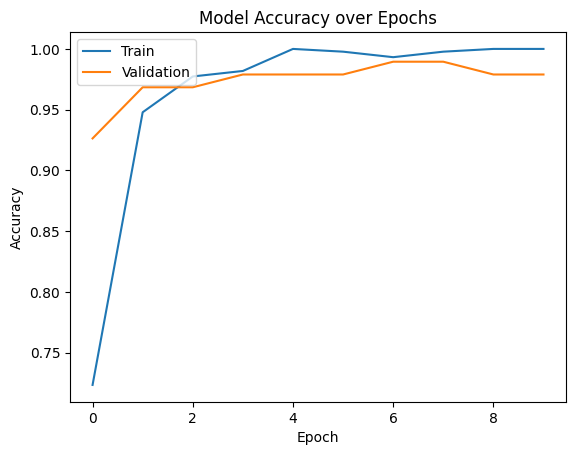

In [23]:
plt.plot(history_1.history['accuracy'])
plt.plot(history_1.history['val_accuracy'])
plt.title('Model Accuracy over Epochs')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

OBSERVATION:

- From the above graph, we see a sharp ramp up of training data performance to 1 by around epoch 4. This may be overfitting on training data.
- The validation data accuracy remains high (~97%) and relatively stable throughout.

Observations suggest that the model may be overfitting the training data, particularly given that training accuracy reaches 100% very quickly, but it's important to consider the validation performance in tandem.

Here’s how we can interpret these results and think about next steps:

### Observations:

1. **Training Accuracy and Overfitting**:

   - Rapid increases in training accuracy, reaching 100% by epoch 4, indicate that the model has learned to perfectly memorize the training dataset. This often suggests overfitting, where the model learns noise and specific patterns unique to the training data rather than generalizable features.
2. **Validation Accuracy**:

   - A validation accuracy around 97% that remains stable suggests that the model is continuing to perform well on unseen data, which is a good sign. However, the gap between training and validation accuracy may still imply some degree of overfitting, depending on the specific loss trends and the size of this gap.

### Recommendations:

1. **Visualize Loss**:

   - Complement accuracy graphs with loss graphs for both training and validation. This will give us a clearer picture of whether the model is overfitting (e.g., training loss drops to near-zero while validation loss fluctuates).
2. **Regularization Techniques**:

   - **Dropout**: Introduce dropout layers in the network to help prevent overfitting by randomly setting a fraction of input units to zero during training.
   - **Weight Regularization**: Consider L1 or L2 regularization in the dense layers to penalize large weights.
3. **Data Augmentation**:

   - Use data augmentation to artificially enlarge the dataset and improve the model's ability to generalize. This could include random rotations, shifts, flips, etc.
4. **Early Stopping**:

   - Implement early stopping based on validation performance to halt training once the model's performance on validation data stops improving, thus preventing overfitting.
5. **Complexity Adjustment**:

   - Simplify the model architecture by reducing the number of units in the dense layer(s) or the number of filters in the convolutional layers, which may help avoid overfitting.

By applying these strategies, we can fine-tune our simple CNN to enhance its generalization to unseen data, ensuring it remains robust and accurate when deployed in real-world scenarios.

Train performance metrics:
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step


,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


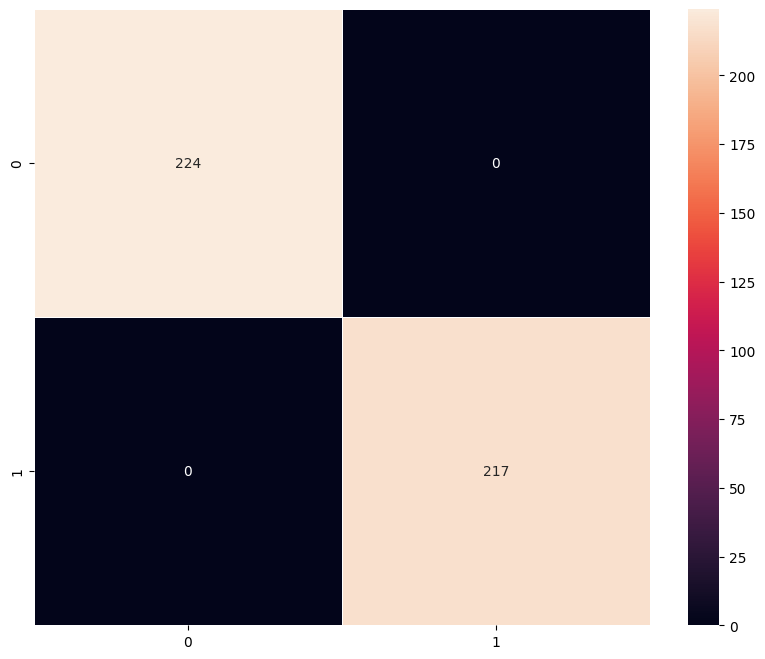

Validation performance metrics:
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.978947,0.978947,0.978947,0.978947



CONFUSION MATRIX

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


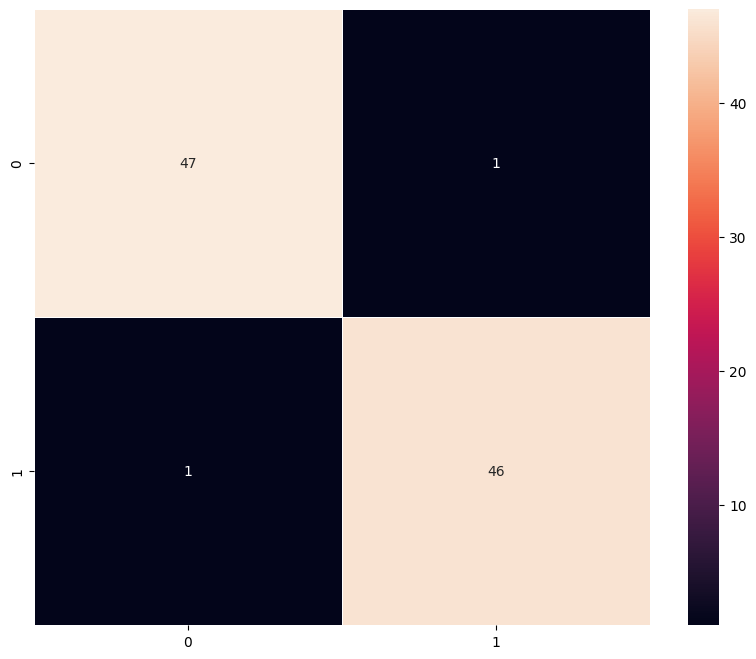

In [24]:
# Evaluate on Train Set
print("Train performance metrics:")
cnn_model_1_train_perf = model_performance_classification(cnn_model_1, X_train, pd.Series(y_train))
display(cnn_model_1_train_perf)

plot_confusion_matrix(cnn_model_1, X_train, pd.Series(y_train))

# Evaluate on Validation Set
print("Validation performance metrics:")
cnn_model_1_val_perf = model_performance_classification(cnn_model_1, X_val, pd.Series(y_val))
display(cnn_model_1_val_perf)

print("\n" + "=" * 60)
print("CONFUSION MATRIX")
print("=" * 60 + "\n") # print separator line

plot_confusion_matrix(cnn_model_1, X_val, pd.Series(y_val))

# Evaluate on Test Set
# print("Test performance metrics:")
# cnn_model_1_test_perf = model_performance_classification(cnn_model_1, X_test, pd.Series(y_test))
# display(cnn_model_1_test_perf)

# print("\n" + "=" * 60)
# print("CONFUSION MATRIX")
# print("=" * 60 + "\n") # print separator line

# plot_confusion_matrix(cnn_model_1, X_test, pd.Series(y_test))

OBSERVATION:

- From the above confusion matrices for the base CNN model we can see it scored perfect on the training data for all performance metrics.
- It may be overfitting on the training data.
  It scored high (~97%) Accuracy on the validation data on the base mode. This may be based on a small image library of 631 images.

Observation is astute. Achieving perfect or near-perfect performance on the training data, while maintaining high accuracy on validation data, especially with a relatively small dataset of 631 images, does indicate potential overfitting.

Here’s how we can address this:

### Observations:

1. **Training Performance**:

   - Scoring perfectly on the training data means the model has likely memorized the training examples rather than learning generalizable features.
2. **Validation Performance**:

   - Achieving high accuracy on a small validation set might not fully reflect the model’s ability to generalize due to the limited diversity of validation samples.
3. **Dataset Size**:

   - With only 631 images, the model might not have sufficient data variety to learn robust, generalizable features, potentially causing it to rely on specific learned patterns instead.

### Strategies to Address Overfitting:

1. **Data Augmentation**:

   - Apply techniques like random rotations, zooms, horizontal flips, and brightness changes to artificially increase the diversity and size of our dataset without collecting more data.
2. **Cross-Validation**:

   - Use k-fold cross-validation to ensure that the model's performance is robust across different subsets of the dataset, providing a more reliable evaluation.
3. **Regularization Techniques**:

   - Incorporate dropout layers and/or L2 regularization to penalize overly complex models, reducing the likelihood of overfitting.
4. **Simplify Model Architecture**:

   - Consider scaling down the current architecture to reduce the risk of the model capturing noise within the training data.
5. **Model Checkpointing and Early Stopping**:

   - Use model checkpoints to save the best model based on validation performance, and implement early stopping to halt training when performance on the validation set deteriorates.
6. **Increase Dataset Size**:

   - If possible, increase the size of our dataset by collecting more images, as more data generally helps in improving model generalization.
7. **Analyze Confusion Matrix**:

   - Study the confusion matrix to understand the types of errors the model is making, which may guide further improvements in data augmentation strategies or model architecture adjustments.

By employing these methods, we can work towards enhancing the model's ability to generalize well to unseen data, making it more robust and reliable for deployment in real-world safety helmet detection applications.

### Vizualizing the predictions

Purpose:

- **Visual debugging:** Did the model predict correctly?
- Model trust: Spot-check whether predictions make visual sense
- Error investigation: If the model misclassifies, was the image ambiguous?

Visualizing predictions is an excellent practice when developing and evaluating machine learning models, especially for image classification tasks like detecting whether workers are wearing helmets.

Here’s how visualizing predictions can serve our model development process:

### Purpose of Visualizing Predictions:

1. **Visual Debugging**:

   - By displaying images alongside their predicted labels, we can quickly ascertain whether the model is producing expected results. This visual check helps identify obvious model failures or successes.
2. **Model Trust**:

   - Spot-checking a sample of predictions allows us to qualitatively assess whether the model's behavior aligns with visual intuition. This can be crucial in building trust in the model's decision-making process, especially in safety-critical applications.
3. **Error Investigation**:

   - When the model produces incorrect predictions, visualizing these errors can provide insights into the types of mistakes it makes:
     - **Ambiguous Images**: Some images may genuinely be too challenging or ambiguous, even for a human.
     - **Pattern Recognition Issues**: Identify instances where the model might be missing specific visual cues or misinterpreting patterns.

### How to Visualize Predictions:

1. **Display a Grid of Images**:

   - Create a grid that pairs and compares actual versus predicted classes. This can be done using libraries like `matplotlib`, `seaborn`, or other visualization tools.
2. **Highlight Errors**:

   - Focus on displaying both correct and incorrect predictions. Errors can be marked or highlighted for easy identification.
3. **Annotation**:

   - Include annotation of images with their true labels and predicted labels to facilitate easy understanding and analysis.
4. **Visual Analysis Across Classes**:

   - Ensure coverage of both classes (“With Helmet” and “Without Helmet”) in our visualizations to assess model performance comprehensively across different categories.

- **Batch Visualization**: Instead of visualizing too many images at once, split them into manageable batches for easier analysis.
- **Filter by Specific Cases**: Consider filtering images by specific criteria, such as the confidence level of the predictions, to focus on potentially ambiguous cases.

By following these practices, we'll be able to glean more insight into model's behavior, ultimately contributing to better performance evaluation and understanding of how well the automated system emulates human visual interpretation in workplace safety contexts.

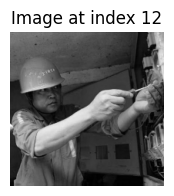

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 645ms/step
Predicted Label: 1
True Label: 1


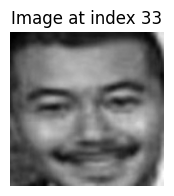

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Predicted Label: 0
True Label: 0


In [25]:
# Visualize and predict for index 12
index = 12
plt.figure(figsize=(2,2))
plt.imshow(X_val[index].reshape(X_val.shape[1], X_val.shape[2]), cmap='gray')
plt.title(f"Image at index {index}")
plt.axis('off')
plt.show()

# Make prediction
prediction = cnn_model_1.predict(X_val[index].reshape(1, X_val.shape[1], X_val.shape[2], 1))
predicted_label = 1 if prediction[0][0] > 0.5 else 0
print('Predicted Label:', predicted_label)
print('True Label:', y_val[index])

# Repeat for index 33
index = 33
plt.figure(figsize=(2,2))
plt.imshow(X_val[index].reshape(X_val.shape[1], X_val.shape[2]), cmap='gray')
plt.title(f"Image at index {index}")
plt.axis('off')
plt.show()

prediction = cnn_model_1.predict(X_val[index].reshape(1, X_val.shape[1], X_val.shape[2], 1))
predicted_label = 1 if prediction[0][0] > 0.5 else 0
print('Predicted Label:', predicted_label)
print('True Label:', y_val[index])

OBSERVATION:

From the above prediction, we can see that the model predicted both images correctly.

Observing that the model correctly predicted both images is a positive sign, indicating that it's learning the relevant features for classifying whether a person is wearing a helmet.

Here are a few things to consider and next steps based on this observation:

### Interpretation:

1. **Correct Predictions**:

   - Correct predictions suggest that model has successfully identified distinguishing features corresponding to the "With Helmet" and "Without Helmet" classes.
2. **Visual Pattern Recognition**:

   - If the visual patterns in the images were clear and the model predicted them accurately, it reinforces that model's learning process is on the right track.

### Next Steps:

1. **Diverse Sample Evaluation**:

   - Ensure to test the model on a wide variety of images that include different conditions, such as various lighting and angles, to further validate its robustness.
2. **Continue Visual Debugging**:

   - Regularly visualize other sets of predictions, especially those from test datasets, to continuously assess the model's performance.
3. **Error Patterns Identification**:

   - While continuously observing correct predictions, also focus on understanding whether there are common patterns in any misclassifications, which could be useful for targeted improvements.
4. **Feedback Loop**:

   - Use insights from correct and incorrect predictions to make iterative improvements to the preprocessing steps, model architecture, or data augmentation strategies.
5. **Quantitative Analysis**:

   - While qualitative checks are useful, support our findings with quantitative performance measures (accuracy, precision, recall) to ensure comprehensive evaluation.

These steps ensure reinforce model's strengths, tackle any weaknesses, and ultimately craft a reliable automated system for helmet detection that aligns with SafeGuard Corp’s objective of enhancing workplace safety.

## Model 2: (VGG-16 (Base))

Use VGG-16 as a frozen feature extractor, then add a small classifier to predict helmet usage.

VGG-16 expects 3-channel (RGB) images. Convert to 3-channel by duplicating the channel.

Using VGG-16 as a frozen feature extractor is a powerful approach, especially since it leverages pre-trained weights learned from a large dataset like ImageNet. By doing so, we can take advantage of high-quality feature maps generated from the first few convolutional layers, which are often general enough to be applicable to various visual recognition tasks, such as helmet detection in this case.

### Steps to Implement:

1. **Prepare Images**:

   - If images are grayscale or single-channel, convert them to 3-channel (RGB) by simply duplicating the single channel across the three channels. This is necessary because VGG-16, as mentioned, requires input data in the form of 3-channel RGB images.
2. **Load VGG-16 Model**:

   - Load the VGG-16 model with pre-trained weights. Importantly, set `include_top=False` to exclude the fully connected layers that are typically used for the classification task in VGG-16.
3. **Freeze the VGG-16 Layers**:

   - Freeze all the layers of the VGG-16 model so that their weights remain unchanged during training. This allows the model to serve as a fixed feature extractor and helps in preventing overfitting when we have a comparatively small dataset.
4. **Add Custom Classifier Layers**:

   - After the VGG-16 base, add our own set of fully connected layers to serve as a classifier. This could include a Flatten layer followed by Dense layers. The last Dense layer should have two units (for the binary classification of helmet detection) with a 'softmax' activation function if we're treating it as two mutually exclusive classes, or a single unit with 'sigmoid' activation for a binary case.
   - Example architecture for the classifier:

     ```
     plaintext
     Flatten()
     Dense(units=256, activation='relu')
     Dropout(rate=0.5)  # Helps in reducing overfitting
     Dense(units=2, activation='softmax')  # For multi-class (or 'sigmoid' for binary)
     ```
5. **Compile the Model**:

   - Compile the entire model using an appropriate loss function ('binary\_crossentropy' for single-label two-class classification) and optimizer (e.g., 'adam').
6. **Train the Model**:

   - Fit the model on our training data with a validation set to monitor its performance. We may choose to use callbacks like early stopping to prevent overfitting.

### Benefits:

- **Transfer Learning**: Leveraging VGG-16's pre-trained features allows us to benefit from robust and well-learned visual features without needing a very large dataset.
- **Efficiency**: By freezing the convolutional base, we reduce training times and computational costs.

### Considerations:

- **Careful Input Preparation**: Ensure our preprocessing pipeline, especially image resizing and channel duplication, is correctly implemented.
- **Experimenting with the Classifier Architecture**: We might need to adjust the size and structure of the dense layers to better fit our specific dataset.

By following these steps and considerations, we can effectively utilize VGG-16 to enhance our model for helmet detection, building on the strong foundation provided by its pre-trained feature extraction capabilities.

In [26]:
# Convert grayscale to RGB-like format for VGG (e.g., (128, 128, 1) → (128, 128, 3))
X_train_vgg = np.repeat(X_train, 3, axis=-1)
X_val_vgg = np.repeat(X_val, 3, axis=-1)
X_test_vgg = np.repeat(X_test, 3, axis=-1)

Load VGG16 without the top classifier

In [27]:
# Load base VGG16 model without top layer
vgg_base = VGG16(weights='imagenet', include_top=False, input_shape=X_train_vgg.shape[1:])

# Freeze all layers first
for layer in vgg_base.layers:
    layer.trainable = False

# Unfreeze the last 4 layers
for layer in vgg_base.layers[-4:]:
    layer.trainable = True

Add Custom Classification Head

In [28]:
# Add custom head
x = vgg_base.output
x = Flatten()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.8)(x)
output = Dense(1, activation='sigmoid')(x)

# Define the final model
cnn_model_2 = Model(inputs=vgg_base.input, outputs=output)

Compile the Model

In [29]:
cnn_model_2.compile(
    optimizer=Adam(learning_rate=0.000001),  # small LR is safer with pre-trained weights
    loss='binary_crossentropy',
    metrics=['accuracy']
)

cnn_model_2.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type) ┃ Output Shape ┃ Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 ( InputLayer ) │ ( None , 200 , 200 , 3 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 ( Conv2D ) │ ( None , 200 , 200 , 64 ) │ 1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 ( Conv2D ) │ ( None , 200 , 200 , 64 ) │ 36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool ( MaxPooling2D ) │ ( None , 100 , 100 , 64 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 ( Conv2D ) │ ( None , 100 , 100 , 128 ) │ 73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 ( Conv2D ) │ ( None , 100 , 100 , 128 ) │ 147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool ( MaxPooling2D ) │ ( None , 50 , 50 , 128 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 ( Conv2D ) │ ( None , 50 , 50 , 256 ) │ 295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 ( Conv2D ) │ ( None , 50 , 50 , 256 ) │ 590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 ( Conv2D ) │ ( None , 50 , 50 , 256 ) │ 590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool ( MaxPooling2D ) │ ( None , 25 , 25 , 256 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 ( Conv2D ) │ ( None , 25 , 25 , 512 ) │ 1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 ( Conv2D ) │ ( None , 25 , 25 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 ( Conv2D ) │ ( None , 25 , 25 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool ( MaxPooling2D ) │ ( None , 12 , 12 , 512 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 ( Conv2D ) │ ( None , 12 , 12 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 ( Conv2D ) │ ( None , 12 , 12 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 ( Conv2D ) │ ( None , 12 , 12 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool ( MaxPooling2D ) │ ( None , 6 , 6 , 512 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 ( Flatten ) │ ( None , 18432 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 ( Dense ) │ ( None , 128 ) │ 2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 ( Dropout ) │ ( None , 128 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 ( Dense ) │ ( None , 1 ) │ 129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 17,074,241 (65.13 MB)

Trainable params: 9,438,977 (36.01 MB)

Non-trainable params: 7,635,264 (29.13 MB)

Train the Model

In [30]:
history_2 = cnn_model_2.fit(
    X_train_vgg, y_train,
    validation_data=(X_val_vgg, y_val),
    epochs=10,
    batch_size=32,
    verbose=2
)

Epoch 1/10
14/14 - 40s - 3s/step - accuracy: 0.5193 - loss: 0.8675 - val_accuracy: 0.4632 - val_loss: 0.7061
Epoch 2/10
14/14 - 5s - 389ms/step - accuracy: 0.4943 - loss: 0.8529 - val_accuracy: 0.5368 - val_loss: 0.6603
Epoch 3/10
14/14 - 5s - 371ms/step - accuracy: 0.5692 - loss: 0.7801 - val_accuracy: 0.6421 - val_loss: 0.6178
Epoch 4/10
14/14 - 3s - 218ms/step - accuracy: 0.5692 - loss: 0.7798 - val_accuracy: 0.8421 - val_loss: 0.5777
Epoch 5/10
14/14 - 3s - 216ms/step - accuracy: 0.6259 - loss: 0.6870 - val_accuracy: 0.8842 - val_loss: 0.5420
Epoch 6/10
14/14 - 5s - 369ms/step - accuracy: 0.6712 - loss: 0.6239 - val_accuracy: 0.9263 - val_loss: 0.5094
Epoch 7/10
14/14 - 5s - 353ms/step - accuracy: 0.6735 - loss: 0.6096 - val_accuracy: 0.9474 - val_loss: 0.4782
Epoch 8/10
14/14 - 5s - 369ms/step - accuracy: 0.6667 - loss: 0.6114 - val_accuracy: 0.9474 - val_loss: 0.4485
Epoch 9/10
14/14 - 5s - 363ms/step - accuracy: 0.6916 - loss: 0.5909 - val_accuracy: 0.9684 - val_loss: 0.4187
Epo

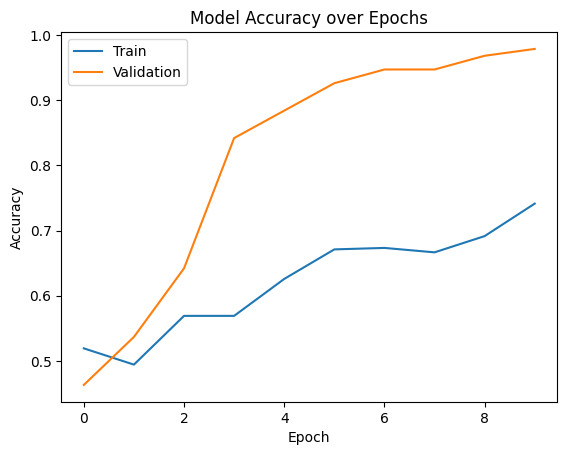

In [31]:
plt.plot(history_2.history['accuracy'])
plt.plot(history_2.history['val_accuracy'])
plt.title('Model Accuracy over Epochs')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

OBSERVATION:

- From the above graph, training continues to step up but peaks around 73% past epoch 8.
- Validation performance continues to rise and may reach even higher with more epochs.
- Validation accuracy is much higher than training accuracy.

Tweak model 2 slightly with additional parameters to see if it makes a difference.

Observations offer valuable insights into the behavior of Model 2, where we are using VGG-16 as a feature extractor with a custom classifier added on top.

The phenomena we're observing can be atypical but are insightful for further model adjustment and optimization:

### Observations:

1. **Training vs. Validation Accuracy**:

   - It's unusual but not impossible for validation accuracy to be higher than training accuracy. This may occur due to several factors like dropout during training (which is turned off during evaluation), or differences in difficulty between the validation and training datasets.
2. **Performance Plateau during Training**:

   - The training accuracy peaking at 73% suggests the model’s capacity or settings may need adjustment for better feature extraction or learning from the data.

### Possible Explanations and Strategies:

1. **Batch Normalization**:

   - If not already in place, consider adding Batch Normalization after convolution layers in the classifier. This can help in stabilizing learning by normalizing inputs to each layer.
2. **Change Dropout Rate**:

   - Review and potentially adjust the dropout rate in the classifier layers. If dropout is too high, it may be excessively hindering learning.
3. **Learning Rate Tuning**:

   - Experiment with the learning rate; perhaps it's too low, causing slow learning in the training phase. A learning rate scheduler or adaptive learning rate can be beneficial.
4. **Data Preparation**:

   - Make sure that our data augmentation techniques and preprocessing are correctly implemented and not causing the training data to appear more complex than the validation set.
5. **Epoch Increase**:

   - Continue training for more epochs with patience, as it appears validation accuracy could still be on an upward trend.
6. **Additional Layers**:

   - Add additional dense layers, or modify the existing number of units, if we believe that complexity could benefit the task at hand within our classifier module.
7. **Error and Data Analysis**:

   - Analyze misclassified instances in both training and validation sets if possible, to identify any commonalities or potential issues with data labeling.

By exploring these strategies, we can address the unusual relationship between training and validation accuracies. Careful tuning and experimentation should help achieve balance and improved performance for our helmet detection task using VGG-16 as a foundational framework.

Evaluate on Train & Validation Only

Train performance metrics:
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 245ms/step


,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 156ms/step


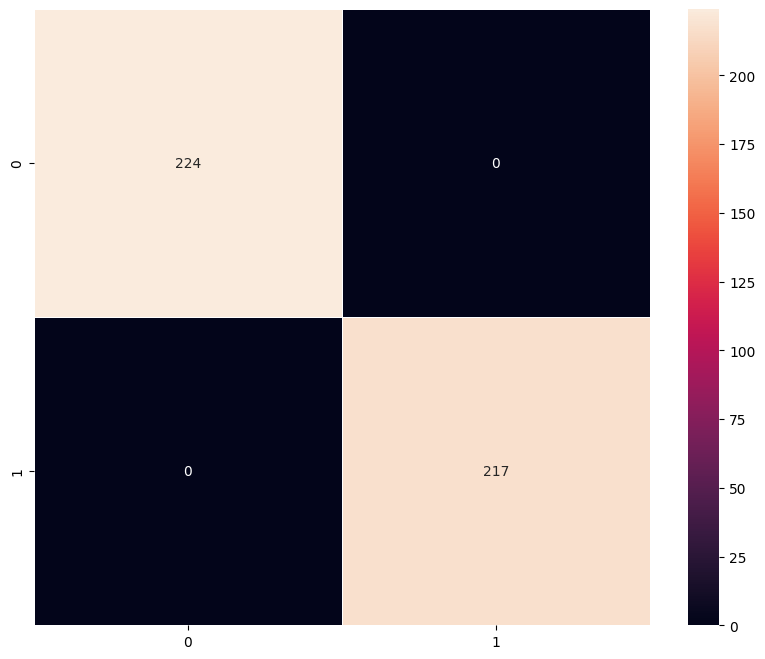

Validation performance metrics:
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 374ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.978947,0.978947,0.979807,0.978943



CONFUSION MATRIX

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 163ms/step


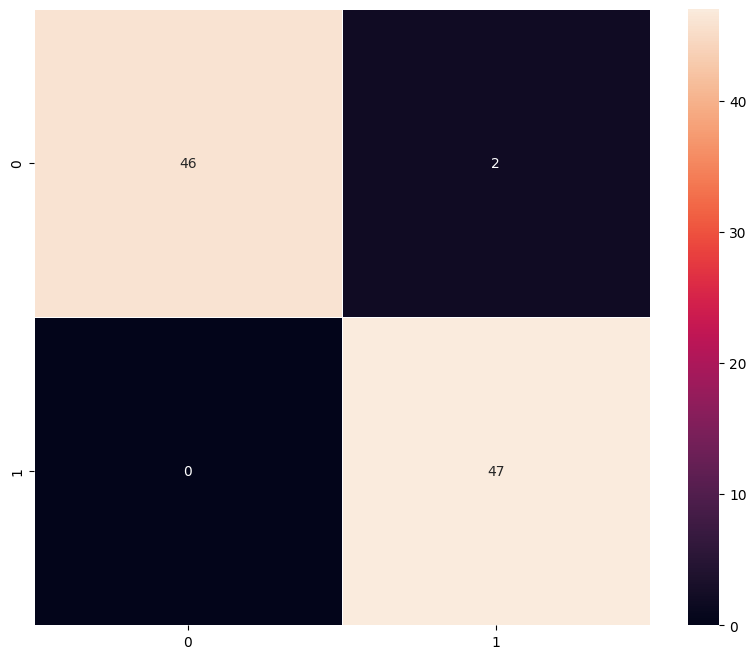

In [32]:
# Evaluate on Train Set
print("Train performance metrics:")
cnn_model_2_train_perf = model_performance_classification(cnn_model_2, X_train_vgg, pd.Series(y_train))
display(cnn_model_2_train_perf)

plot_confusion_matrix(cnn_model_2, X_train_vgg, pd.Series(y_train))

# Evaluate on Validation Set
print("Validation performance metrics:")
cnn_model_2_val_perf = model_performance_classification(cnn_model_2, X_val_vgg, pd.Series(y_val))
display(cnn_model_2_val_perf)

print("\n" + "=" * 60)
print("CONFUSION MATRIX")
print("=" * 60 + "\n")  # print separator line

plot_confusion_matrix(cnn_model_2, X_val_vgg, pd.Series(y_val))

# Hold off on Test Set — uncomment only when ready to evaluate final model
# print("Test performance metrics:")
# cnn_model_2_test_perf = model_performance_classification(cnn_model_2, X_test_vgg, pd.Series(y_test))
# display(cnn_model_2_test_perf)

# print("\n" + "=" * 60)
# print("CONFUSION MATRIX")
# print("=" * 60 + "\n")

# plot_confusion_matrix(cnn_model_2, X_test_vgg, pd.Series(y_test))

Print class distributions to ensure my data is still balanced due to high scores.

In [33]:
print("Train:", np.bincount(y_train))
print("Val:", np.bincount(y_val))
print("Test:", np.bincount(y_test))

Train: [224 217]
Val: [48 47]
Test: [48 47]


### Visualizing the prediction:

Purpose:

- **Visual debugging:** Did the model predict correctly?
- Model trust: Spot-check whether predictions make visual sense
- Error investigation: If the model misclassifies, was the image ambiguous?

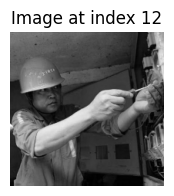

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Label: 1
True Label: 1


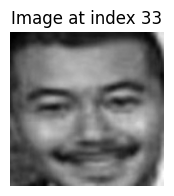

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Predicted Label: 0
True Label: 0


In [34]:
# For index 12
index = 12
plt.figure(figsize=(2, 2))
plt.imshow(X_val[index].reshape(X_val.shape[1], X_val.shape[2]), cmap='gray')  # grayscale view
plt.title(f"Image at index {index}")
plt.axis('off')
plt.show()

# Predict using the RGB-converted version
prediction = cnn_model_2.predict(X_val_vgg[index].reshape(1, X_val.shape[1], X_val.shape[2], 3))
predicted_label = 1 if prediction[0][0] > 0.5 else 0
print('Predicted Label:', predicted_label)
print('True Label:', y_val[index])

# For index 33
index = 33
plt.figure(figsize=(2, 2))
plt.imshow(X_val[index].reshape(X_val.shape[1], X_val.shape[2]), cmap='gray')  # grayscale view
plt.title(f"Image at index {index}")
plt.axis('off')
plt.show()

prediction = cnn_model_2.predict(X_val_vgg[index].reshape(1, X_val.shape[1], X_val.shape[2], 3))
predicted_label = 1 if prediction[0][0] > 0.5 else 0
print('Predicted Label:', predicted_label)
print('True Label:', y_val[index])

OBSERVATION:

From the above prediction, we can see that the model predicted both images correctly.

Correct predictions on both images indicate that the model, using VGG-16 as a feature extractor, is effectively distinguishing between images of workers with and without helmets.

Here are a few considerations and next steps based on these successful predictions:

### Considerations:

1. **Confirm Ongoing Performance**:

   - While correct predictions on a small subset are encouraging, it's essential to consistently evaluate how the model performs across a larger set of test images.
2. **Test with Diverse Images**:

   - Ensure that the test images represent a variety of conditions found at real worksites—different lighting, angles, and visible obstructions—so we can be confident in the model's real-world applicability.
3. **Error Analysis**:

   - Complement successful predictions by focusing also on any errors the model might be making, to continue refining classification accuracy.

### Next Steps:

1. **Expand Testing**:

   - Broaden the testing dataset range to include more samples, especially borderline cases where the helmet status might be ambiguous or less clear.
2. **Model Fine-Tuning**:

   - Depending on the performance metrics and any existing misclassifications, consider fine-tuning the top classifier layers or experimenting with data augmentation techniques to further enhance robustness.
3. **Examine Model Confidence**:

   - Examine confidence levels of the predictions to better understand over which images the model is most certain or uncertain in its predictions.
4. **Deploy in Simulated Environment**:

   - If possible, deploy the model in a controlled but diverse test environment to validate its real-world effectiveness further.
5. **Present Findings**:

   - Compile both qualitative and quantitative results to present to stakeholders, demonstrating the model's capability in achieving the business objective of improving workplace safety through automated image analysis.

Overall, building on this success by systematically expanding testing and validation will help reinforce the model's deployment readiness and ongoing improvements.

## Model 3: (VGG-16 (Base + FFNN))

- This model is often stronger for small datasets where feature extraction needs a bit more modeling power to separate decision boundaries.
- Lets us test if it benefits from a deeper classification head vs. the simple head in cnn\_model\_2

Building upon the VGG-16 architecture by adding a more complex Fully Connected Neural Network (FFNN) as the classification head is a strategic approach, especially when we have a smaller dataset and we want to enhance the model's ability to differentiate between subtle features in the images.

Here's we can go about it:

### Key Considerations for Model 3:

1. **Complexity Balance**:
   - By adding additional layers and units in the FFNN portion of the model, we aim to empower it to learn more intricate decision boundaries that the simpler head may not capture.

### Steps to Implement and Optimize the FFNN Head:

1. **Load VGG-16 as Base Model**:

   - As before, load the VGG-16 model with pre-trained weights, excluding the top classification layers to serve as a feature extractor.
2. **Build a Deeper Classification Head**:

   - Design a deeper FFNN to serve as the top classifier, connecting to the VGG-16 feature outputs.
   - This could include multiple Dense layers with increasing or varying units, depending on our architecture choices.

   Example:

   ```
   plaintext
   Flatten()
   Dense(units=512, activation='relu')  # More units for deeper learning
   Dropout(rate=0.5)  # Regularization to prevent overfitting
   Dense(units=256, activation='relu')
   Dropout(rate=0.5)
   Dense(units=2, activation='softmax')  # Or use 'sigmoid' for binary
   ```
3. **Compile the Model**:

   - Use an appropriate optimizer (e.g., 'adam') and loss function ('binary\_crossentropy' for two classes) to compile this more complex model.
4. **Training and Validation**:

   - Train the model with attention to ensuring sufficient epochs for learning deeper features, using validation performance to monitor and adjust.
5. **Hyperparameter Tuning**:

   - Experiment with the number of layers, units per layer, dropout rates, and learning rates to find an optimal configuration.
6. **Monitor for Overfitting**:

   - Although the deeper FFNN can better capture intricate features, it also needs careful monitoring for overfitting, calling for methods like early stopping and more data augmentation.

### Expected Benefits:

- **Improved Feature Learning**: By having a deeper classification head, the model gains capacity to discern complex patterns within the feature set provided by VGG-16.
- **Enhanced Flexibility**: This setup allows the model to adjust to the nuances of our specific dataset more effectively than a simpler model might.

### Next Steps:

- **Experimentation and Analysis**: After model training, analyze performance metrics along with confusion matrices to identify potential improvements.
- **Iterative Development**: Continually refine the FFNN setup in response to model performance and insights from error analysis.

This approach, leveraging a stronger classification head, is geared towards improving prediction accuracy and robustness, particularly when working with limited dataset sizes, as it empowers the model to make more precise distinctions between complex image classes.

In [35]:
# Convert grayscale to RGB-like format for VGG (e.g., (128, 128, 1) → (128, 128, 3))
X_train_vgg = np.repeat(X_train, 3, axis=-1)
X_val_vgg = np.repeat(X_val, 3, axis=-1)
X_test_vgg = np.repeat(X_test, 3, axis=-1)

Load VGG16 without the top classifier

In [36]:
# Load base VGG16 model without top layer
vgg_base = VGG16(weights='imagenet', include_top=False, input_shape=X_train_vgg.shape[1:])

# Freeze all layers first
for layer in vgg_base.layers:
    layer.trainable = False

# Unfreeze the last 4 layers
# for layer in vgg_base.layers[-4:]:
#   layer.trainable = True

Add a Deeper FFNN Head

In [37]:
# Add a Deeper FFNN Head
x = vgg_base.output
x = Flatten()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.7)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.8)(x)
output = Dense(1, activation='sigmoid')(x)

Compile the Model

In [38]:
# Define the final model
cnn_model_3 = Model(inputs=vgg_base.input, outputs=output)

cnn_model_3.compile(
    optimizer=Adam(learning_rate=0.00001),  # small LR is safer with pre-trained weights
    loss='binary_crossentropy',
    metrics=['accuracy']
)

cnn_model_3.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type) ┃ Output Shape ┃ Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 ( InputLayer ) │ ( None , 200 , 200 , 3 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 ( Conv2D ) │ ( None , 200 , 200 , 64 ) │ 1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 ( Conv2D ) │ ( None , 200 , 200 , 64 ) │ 36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool ( MaxPooling2D ) │ ( None , 100 , 100 , 64 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 ( Conv2D ) │ ( None , 100 , 100 , 128 ) │ 73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 ( Conv2D ) │ ( None , 100 , 100 , 128 ) │ 147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool ( MaxPooling2D ) │ ( None , 50 , 50 , 128 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 ( Conv2D ) │ ( None , 50 , 50 , 256 ) │ 295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 ( Conv2D ) │ ( None , 50 , 50 , 256 ) │ 590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 ( Conv2D ) │ ( None , 50 , 50 , 256 ) │ 590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool ( MaxPooling2D ) │ ( None , 25 , 25 , 256 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 ( Conv2D ) │ ( None , 25 , 25 , 512 ) │ 1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 ( Conv2D ) │ ( None , 25 , 25 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 ( Conv2D ) │ ( None , 25 , 25 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool ( MaxPooling2D ) │ ( None , 12 , 12 , 512 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 ( Conv2D ) │ ( None , 12 , 12 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 ( Conv2D ) │ ( None , 12 , 12 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 ( Conv2D ) │ ( None , 12 , 12 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool ( MaxPooling2D ) │ ( None , 6 , 6 , 512 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 ( Flatten ) │ ( None , 18432 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 ( Dense ) │ ( None , 256 ) │ 4,718,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 ( Dropout ) │ ( None , 256 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 ( Dense ) │ ( None , 128 ) │ 32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 ( Dropout ) │ ( None , 128 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 ( Dense ) │ ( None , 1 ) │ 129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 19,466,561 (74.26 MB)

Trainable params: 4,751,873 (18.13 MB)

Non-trainable params: 14,714,688 (56.13 MB)

Train the Model

In [39]:
history_3 = cnn_model_3.fit(
    X_train_vgg, y_train,
    validation_data=(X_val_vgg, y_val),
    epochs=10,
    batch_size=32,
    verbose=2
)

Epoch 1/10
14/14 - 10s - 697ms/step - accuracy: 0.5238 - loss: 1.1254 - val_accuracy: 0.8421 - val_loss: 0.5862
Epoch 2/10
14/14 - 5s - 340ms/step - accuracy: 0.5828 - loss: 1.0004 - val_accuracy: 0.9053 - val_loss: 0.5168
Epoch 3/10
14/14 - 3s - 199ms/step - accuracy: 0.5873 - loss: 0.8331 - val_accuracy: 0.8842 - val_loss: 0.4711
Epoch 4/10
14/14 - 3s - 202ms/step - accuracy: 0.5782 - loss: 0.7858 - val_accuracy: 0.9263 - val_loss: 0.4357
Epoch 5/10
14/14 - 3s - 205ms/step - accuracy: 0.6372 - loss: 0.7254 - val_accuracy: 0.9474 - val_loss: 0.3974
Epoch 6/10
14/14 - 5s - 375ms/step - accuracy: 0.6712 - loss: 0.6407 - val_accuracy: 0.9789 - val_loss: 0.3624
Epoch 7/10
14/14 - 3s - 204ms/step - accuracy: 0.7347 - loss: 0.5550 - val_accuracy: 0.9789 - val_loss: 0.3373
Epoch 8/10
14/14 - 3s - 204ms/step - accuracy: 0.7324 - loss: 0.5385 - val_accuracy: 0.9789 - val_loss: 0.3166
Epoch 9/10
14/14 - 3s - 207ms/step - accuracy: 0.7619 - loss: 0.4887 - val_accuracy: 0.9895 - val_loss: 0.2904


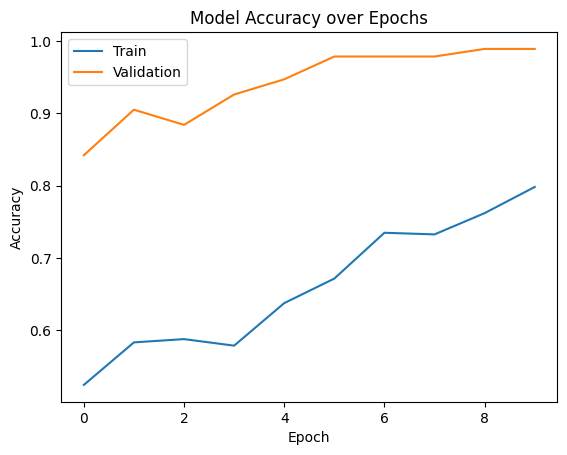

In [40]:
plt.plot(history_3.history['accuracy'])
plt.plot(history_3.history['val_accuracy'])
plt.title('Model Accuracy over Epochs')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

OBSERVATION:

- The training data accuracy continues to rise to about 79% around epoch 9.
- From the above graph, we see a sharp ramp up of validation data performance to close to 1 by around epoch 5 and then remain stable.
- Like model 2, validation data performance continued higher than training data through the training process.

This observation where the validation accuracy surpasses training accuracy can be intriguing and suggests a few things about Model 3's behavior.

Let's explore the situation we're encountering:

### Observations & Potential Causes:

1. **Validation Accuracy Higher than Training**:

   - Validation performance exceeding the training accuracy might occur due to increased variance or noise in the training data compared to validation data.
   - It's possible that the regularization techniques (like dropout) during training are causing this discrepancy, as they are typically turned off during validation.
2. **Stability in Validation Performance**:

   - The early stabilization of the validation accuracy suggests the model can generalize well, likely due to the effective learning of the feature representations by the FFNN layered classifier.

### Actions and Considerations:

1. **Model Complexity**:

   - Re-evaluate the model's complexity in the FFNN head. It might be optimized further to bridge the performance gap by either increasing the layer depth or tuning the number of units.
2. **Regularization Effects**:

   - Review regularization parameters like dropout rates used during training, as these can lead to differences between training and validation performances.
3. **Data Quality**:

   - Consider any differences between training and validation data that might contribute to this behavior. Ensure they are similarly distributed and representative of the same input space.
4. **Validate with Additional Metrics**:

   - Beyond accuracy alone, we might consider precision, recall, and F1-score measurements to gain a more rounded view of model performance.
5. **Investigate Training Dynamics**:

   - Observe loss curves to understand if the training data perhaps has more noise or challenging instances leading to lower accuracy.
6. **Training Set Analysis**:

   - Conduct a thorough examination of training data to ensure there aren't mislabeled or particularly noisy images impeding learning.
7. **Learning Rate Adjustments**:

   - Consider fine-tuning the learning rate to enhance learning on the training set. A learning rate schedule might also help manage performance across epochs.

### Next Steps:

- **Experiment and Refine**: Try small iterative tweaks in our FFNN architecture and training regimen to better balance between fitting the training data and generalizing well (as seen with validation).
- **Insight Generation**: Consider running additional diagnostics to better understand why validation remains strong, and whether it translates into real-world performance.

By addressing these areas, we can more effectively navigate the nuances of our model's performance and ensure it is optimized to not only learn from the training data but continue performing robustly on unseen data.

Evaluate on Train & Validation Only (NOT test yet!)

Train performance metrics:
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 250ms/step


,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step


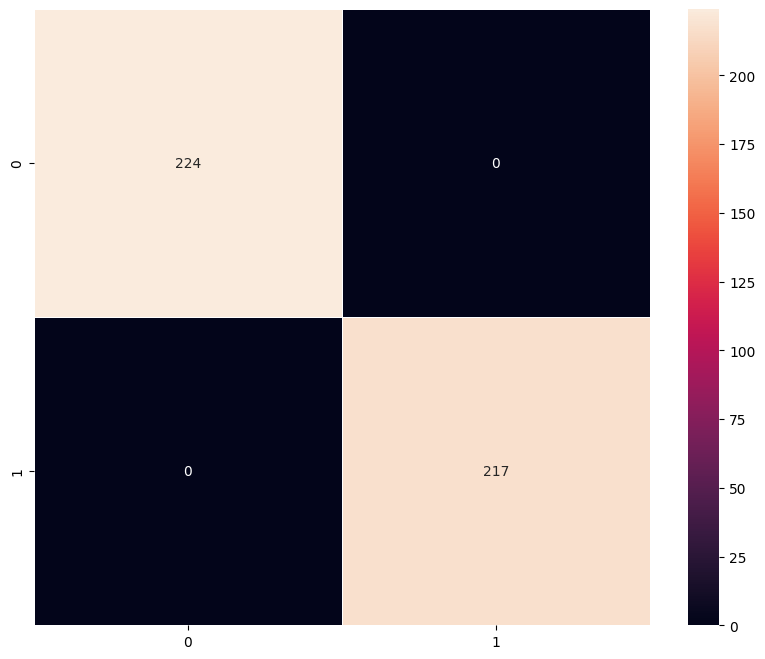


Validation performance metrics:
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 374ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.989474,0.989474,0.989689,0.989471



3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step


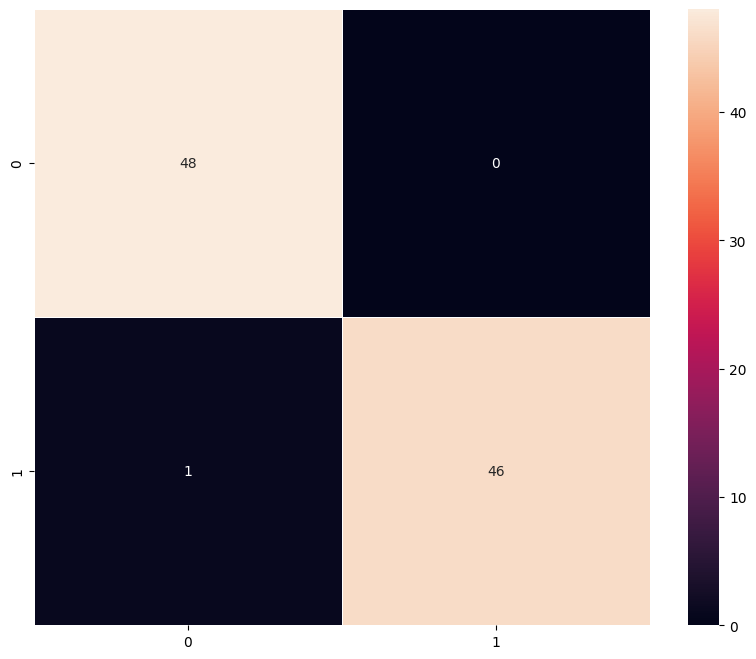

In [41]:
print("Train performance metrics:")
cnn_model_3_train_perf = model_performance_classification(cnn_model_3, X_train_vgg, pd.Series(y_train))
display(cnn_model_3_train_perf)

plot_confusion_matrix(cnn_model_3, X_train_vgg, pd.Series(y_train))

print("\nValidation performance metrics:")
cnn_model_3_val_perf = model_performance_classification(cnn_model_3, X_val_vgg, pd.Series(y_val))
display(cnn_model_3_val_perf)

print("\n" + "="*60)
plot_confusion_matrix(cnn_model_3, X_val_vgg, pd.Series(y_val))

Print class distributions to ensure my data is still balanced due to high scores.

In [42]:
print("Train:", np.bincount(y_train))
print("Val:", np.bincount(y_val))
print("Test:", np.bincount(y_test))

Train: [224 217]
Val: [48 47]
Test: [48 47]


#### Visualizing the predictions

Purpose:

- Visual debugging: Did the model predict correctly?
- Model trust: Spot-check whether predictions make visual sense
- Error investigation: If the model misclassifies, was the image ambiguous?

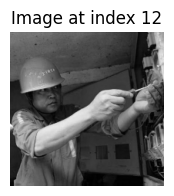

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Predicted Label: 1
True Label: 1


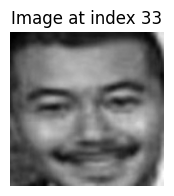

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Predicted Label: 0
True Label: 0


In [43]:
# For index 12
index = 12
plt.figure(figsize=(2, 2))
plt.imshow(X_val[index].reshape(X_val.shape[1], X_val.shape[2]), cmap='gray')  # grayscale view
plt.title(f"Image at index {index}")
plt.axis('off')
plt.show()

# Predict using the RGB-converted version
prediction = cnn_model_2.predict(X_val_vgg[index].reshape(1, X_val.shape[1], X_val.shape[2], 3))
predicted_label = 1 if prediction[0][0] > 0.5 else 0
print('Predicted Label:', predicted_label)
print('True Label:', y_val[index])

# For index 33
index = 33
plt.figure(figsize=(2, 2))
plt.imshow(X_val[index].reshape(X_val.shape[1], X_val.shape[2]), cmap='gray')  # grayscale view
plt.title(f"Image at index {index}")
plt.axis('off')
plt.show()

prediction = cnn_model_2.predict(X_val_vgg[index].reshape(1, X_val.shape[1], X_val.shape[2], 3))
predicted_label = 1 if prediction[0][0] > 0.5 else 0
print('Predicted Label:', predicted_label)
print('True Label:', y_val[index])

OBSERVATION:

From the above prediction, we can see that the model predicted both images correctly.

It's great to see that Model 3 is predicting images correctly! This indicates that adding a more complex Fully Connected Neural Network (FFNN) head to the VGG-16 base has enhanced its ability to accurately classify images as showing workers either with or without helmets.

Here are some considerations and next steps based on this observation:

### Considerations:

1. **Model Efficacy**:

   - The correct predictions suggest that the increased modeling power of the deeper FFNN is effectively capturing the necessary features for distinguishing between the two classes.
2. **Continued Evaluation**:

   - While successful predictions for individual images are promising, it’s crucial to ensure that this performance generalizes across the entire test dataset.

### Next Steps:

1. **Broader Testing**:

   - Evaluate the model on a larger and more varied test dataset to ensure consistent performance across different scenarios, including variations in lighting, angles, and worker postures.
2. **Review Model Complexity**:

   - Even if the model performs well, continue evaluating whether the complexity of the FFNN is appropriate by monitoring for overfitting symptoms as we increase our dataset size or variability.
3. **Analyze Confidence Levels**:

   - Review model confidence levels for its predictions. This can help determine how certain the model is in its classifications, providing insight into possible strengths and weaknesses.
4. **Deploy Iteratively**:

   - Consider deploying the model in a controlled pilot setting, capturing real-time image data to further validate and refine before full-scale deployment.
5. **Feature Importance**:

   - If possible, investigate which features or parts of the image contribute most significantly to the model's decision process to ensure alignment with expected safety-monitoring attributes.
6. **Collaborative Feedback**:

   - Gather feedback from domain experts or stakeholders to ensure that the model’s performance meets real-world operational needs and expectations.

Successfully navigating these steps will help establish the robustness, accuracy, and general readiness of our model for real-world application in enhancing workplace safety through effective helmet detection.

## Model 4: (VGG-16 (Base + FFNN + Data Augmentation)

- In most of the real-world case studies, it is challenging to acquire a large number of images and then train CNNs.
- To overcome this problem, one approach we might consider is **Data Augmentation**.
- CNNs have the property of **translational invariance**, which means they can recognise an object even if its appearance shifts translationally in some way. - Taking this attribute into account, we can augment the images using the techniques listed below

  - Horizontal Flip (should be set to True/False)
  - Vertical Flip (should be set to True/False)
  - Height Shift (should be between 0 and 1)
  - Width Shift (should be between 0 and 1)
  - Rotation (should be between 0 and 180)
  - Shear (should be between 0 and 1)
  - Zoom (should be between 0 and 1) etc.

Remember, **data augmentation should not be used in the validation/test data set**.

Data augmentation is a valuable strategy to enhance model generalization, particularly when dealing with small datasets. By artificially expanding our training set with variations, we can help the model become robust to different transformations and improve its ability to generalize to unseen data.

Here’s how to implement data augmentation effectively:

### Steps for Implementing Data Augmentation with Model 4:

1. **Augmentation Techniques**:

   - Utilize a library, such as Keras’ `ImageDataGenerator`, to apply various augmentations. Here's how we can configure some of the common transformations:
     - **Horizontal Flip**: Randomly flip images horizontally.
     - **Vertical Flip**: Randomly flip images vertically.
     - **Height Shift**: Randomly shift images vertically within a proportion, e.g., `0.1` for a 10% shift.
     - **Width Shift**: Randomly shift images horizontally within a proportion.
     - **Rotation**: Randomly rotate images up to a specified degree, e.g., `40` for rotations between -40 and 40 degrees.
     - **Shear**: Apply a shear transformation within a specified range.
     - **Zoom**: Randomly zoom images within a given range.
2. **Setup ImageDataGenerator**:

   - Configure an `ImageDataGenerator` for training data.
   - Ensure augmentations are only applied to the training data, not to validation or test data.

   ```
   from keras.preprocessing.image import ImageDataGenerator

   train_datagen = ImageDataGenerator(
       horizontal_flip=True,
       vertical_flip=False,
       rotation_range=40,
       width_shift_range=0.2,
       height_shift_range=0.2,
       shear_range=0.2,
       zoom_range=0.2,
       fill_mode='nearest'
   )
   ```
3. **Integrate with the Model**:

   - Apply this data generator while fitting the model by using the `.flow()` method to iterate over the augmented data batches.
4. **Fit the Model**:

   - Use the data generator in the model's `.fit()` or `.fit_generator()` method, depending on our Keras version.

   ```
   history = model.fit(
       train_datagen.flow(x_train, y_train, batch_size=32),
       validation_data=(x_val, y_val),
       steps_per_epoch=len(x_train) // 32,
       epochs=50
   )
   ```

### Benefits of Data Augmentation:

- **Enhanced Generalization**: Augmentation helps the model generalize better to different lighting, orientations, and partial occlusions.
- **Robust Learning**: Gives the model more varied data scenarios to learn from, mimicking possible real-world conditions.

### Considerations:

- **Balance of Augmentation**: Over-augmentation can lead to the model learning noise, so customize augmentation settings carefully.
- **Performance Monitoring**: Keep an eye on both training and validation performance to ensure that augmentation is beneficial.

### Conclusion:

Using data augmentation in Model 4 builds on the strengths of VGG-16 and the FFNN architecture, enabling improved robustness and accuracy in detection tasks, even when dataset sizes are comparatively small. This multi-faceted approach aims to enhance the model’s proficiency in accurately identifying helmet usage in variable real-world scenarios.

In [44]:
# Convert grayscale to RGB-like format for VGG (e.g., (128, 128, 1) → (128, 128, 3))
X_train_vgg = np.repeat(X_train, 3, axis=-1)
X_val_vgg = np.repeat(X_val, 3, axis=-1)
X_test_vgg = np.repeat(X_test, 3, axis=-1)

Define ImageDataGenerator for Augmentation

In [45]:
# Data augmentation only applied to training data
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Validation/Test generators (no augmentation)
val_datagen = ImageDataGenerator()

# Flow from arrays
train_generator = train_datagen.flow(X_train_vgg, y_train, batch_size=32)
val_generator = val_datagen.flow(X_val_vgg, y_val, batch_size=32)

Load VGG16 without the top classifier (reuse from cnn\_model\_3)

In [46]:
vgg_base = VGG16(weights='imagenet', include_top=False, input_shape=X_train_vgg.shape[1:])
for layer in vgg_base.layers:
    layer.trainable = False

x = vgg_base.output
x = Flatten()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.7)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.8)(x)
output = Dense(1, activation='sigmoid')(x)

cnn_model_4 = Model(inputs=vgg_base.input, outputs=output)

Compile the Model

In [47]:
# Define the final model
cnn_model_4 = Model(inputs=vgg_base.input, outputs=output)

cnn_model_4.compile(
    optimizer=Adam(learning_rate=0.000001),  # small LR is safer with pre-trained weights
    loss='binary_crossentropy',
    metrics=['accuracy']
)

cnn_model_4.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type) ┃ Output Shape ┃ Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 ( InputLayer ) │ ( None , 200 , 200 , 3 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 ( Conv2D ) │ ( None , 200 , 200 , 64 ) │ 1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 ( Conv2D ) │ ( None , 200 , 200 , 64 ) │ 36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool ( MaxPooling2D ) │ ( None , 100 , 100 , 64 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 ( Conv2D ) │ ( None , 100 , 100 , 128 ) │ 73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 ( Conv2D ) │ ( None , 100 , 100 , 128 ) │ 147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool ( MaxPooling2D ) │ ( None , 50 , 50 , 128 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 ( Conv2D ) │ ( None , 50 , 50 , 256 ) │ 295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 ( Conv2D ) │ ( None , 50 , 50 , 256 ) │ 590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 ( Conv2D ) │ ( None , 50 , 50 , 256 ) │ 590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool ( MaxPooling2D ) │ ( None , 25 , 25 , 256 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 ( Conv2D ) │ ( None , 25 , 25 , 512 ) │ 1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 ( Conv2D ) │ ( None , 25 , 25 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 ( Conv2D ) │ ( None , 25 , 25 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool ( MaxPooling2D ) │ ( None , 12 , 12 , 512 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 ( Conv2D ) │ ( None , 12 , 12 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 ( Conv2D ) │ ( None , 12 , 12 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 ( Conv2D ) │ ( None , 12 , 12 , 512 ) │ 2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool ( MaxPooling2D ) │ ( None , 6 , 6 , 512 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 ( Flatten ) │ ( None , 18432 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 ( Dense ) │ ( None , 256 ) │ 4,718,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 ( Dropout ) │ ( None , 256 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 ( Dense ) │ ( None , 128 ) │ 32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 ( Dropout ) │ ( None , 128 ) │ 0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 ( Dense ) │ ( None , 1 ) │ 129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 19,466,561 (74.26 MB)

Trainable params: 4,751,873 (18.13 MB)

Non-trainable params: 14,714,688 (56.13 MB)

Train the Model

In [48]:
history_4 = cnn_model_4.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    verbose=2
)

Epoch 1/10
14/14 - 12s - 882ms/step - accuracy: 0.4830 - loss: 1.4582 - val_accuracy: 0.5368 - val_loss: 0.7142
Epoch 2/10
14/14 - 5s - 374ms/step - accuracy: 0.5079 - loss: 1.4118 - val_accuracy: 0.5579 - val_loss: 0.7033
Epoch 3/10
14/14 - 10s - 705ms/step - accuracy: 0.4512 - loss: 1.4290 - val_accuracy: 0.6000 - val_loss: 0.6919
Epoch 4/10
14/14 - 6s - 432ms/step - accuracy: 0.5283 - loss: 1.2546 - val_accuracy: 0.6105 - val_loss: 0.6822
Epoch 5/10
14/14 - 5s - 346ms/step - accuracy: 0.4875 - loss: 1.4474 - val_accuracy: 0.6211 - val_loss: 0.6721
Epoch 6/10
14/14 - 5s - 373ms/step - accuracy: 0.4966 - loss: 1.2656 - val_accuracy: 0.6421 - val_loss: 0.6630
Epoch 7/10
14/14 - 6s - 409ms/step - accuracy: 0.5374 - loss: 1.3086 - val_accuracy: 0.6737 - val_loss: 0.6548
Epoch 8/10
14/14 - 11s - 755ms/step - accuracy: 0.5147 - loss: 1.2220 - val_accuracy: 0.6947 - val_loss: 0.6476
Epoch 9/10
14/14 - 5s - 346ms/step - accuracy: 0.5125 - loss: 1.1905 - val_accuracy: 0.7158 - val_loss: 0.640

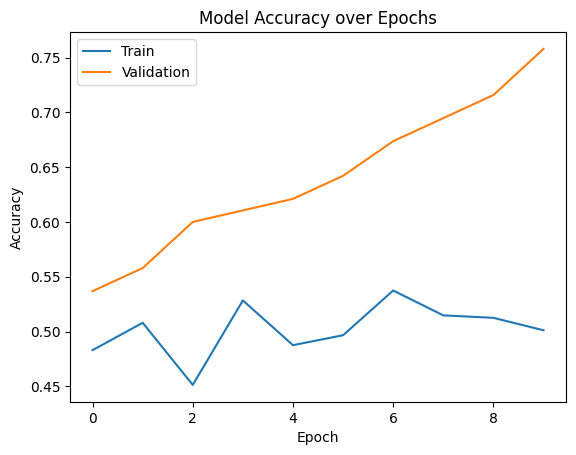

In [49]:
plt.plot(history_4.history['accuracy'])
plt.plot(history_4.history['val_accuracy'])
plt.title('Model Accuracy over Epochs')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

OBSERVATION:

Training accuracy fluctuates heavily, never exceeding ~53%
Validation accuracy is continuing to rise and may benefit from more epochs.

Fluctuations in training accuracy, especially when validation accuracy shows improvement, can be indicative of several underlying issues or considerations in the training process. Here are some insights into what's happening with Model 4 and strategies to address the situation:

### Observations and Potential Causes:

1. **Data Augmentation Impact**:

   - The heavy fluctuations in training accuracy could be due to strong data augmentation. This makes the training set very diverse, introducing significant variance in the samples seen in each epoch, which can confuse the model during learning.
2. **Model Underfitting**:

   - The low training accuracy suggests the model may be underfitting, potentially due to an overly complex augmentation or an insufficiently complex model to capture the nuances introduced by augmentation.
3. **Regularization and Optimization**:

   - Fluctuations may arise from dropout layers or other regularization techniques. Learning rate tuning and other hyperparameters could also influence these results.

### Strategies for Addressing the Issue:

1. **Adjust Data Augmentation**:

   - Reassess the intensity and types of augmentations to not overly distort images.
   - Consider reducing the range of some augmentations such as rotation, zoom, or shift.
2. **Optimize Learning Rate**:

   - Experiment with a learning rate schedule or adaptive learning rates to stabilize and improve model convergence.
3. **Batch Size and Training Steps**:

   - Evaluate the batch size and augment it according to our computational resources, potentially impacting stability and performance.
   - Consider adjusting `steps_per_epoch` in line with the augmentation strategy to ensure diverse training data batches.
4. **Model Complexity**:

   - Evaluate whether the classifier's FFNN complexity suffices. More units or additional layers might help capture intricate patterns better, reducing underfitting.
5. **Regularization Review**:

   - Tweak dropout rates and evaluate their effects on training stability.
   - Add or modify Batch Normalization layers to help stabilize training dynamics.
6. **Additional Epochs**:

   - Extend training to more epochs, as we observed potential improvements in validation accuracy.

### Next Steps for Validation:

1. **Monitor and Visualize**:

   - Plot the learning curves for both train and validation to better understand their dynamics over successive epochs. This can help gauge where modifications may be beneficial.
2. **Validation Improvement Check**:

   - As validation accuracy is improving, ensure the dataset—is representative and assess whether the augmentations are translating well to unseen data for real-world application purposes.

By focusing on these strategic adjustments, we can ensure that Model 4 is not only diverse in learning but also effectively bridges the gap to reduce fluctuations during training, ultimately enhancing both robustness and accuracy in classification tasks.

Evaluate on Train & Validation Only

14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 211ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 377ms/step
Training performance:
              precision    recall  f1-score   support

           0       0.66      0.97      0.79       224
           1       0.94      0.49      0.65       217

    accuracy                           0.73       441
   macro avg       0.80      0.73      0.72       441
weighted avg       0.80      0.73      0.72       441


Validation performance:
              precision    recall  f1-score   support

           0       0.69      0.96      0.80        48
           1       0.93      0.55      0.69        47

    accuracy                           0.76        95
   macro avg       0.81      0.76      0.75        95
weighted avg       0.81      0.76      0.75        95


Validation Confusion Matrix:
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 167ms/step


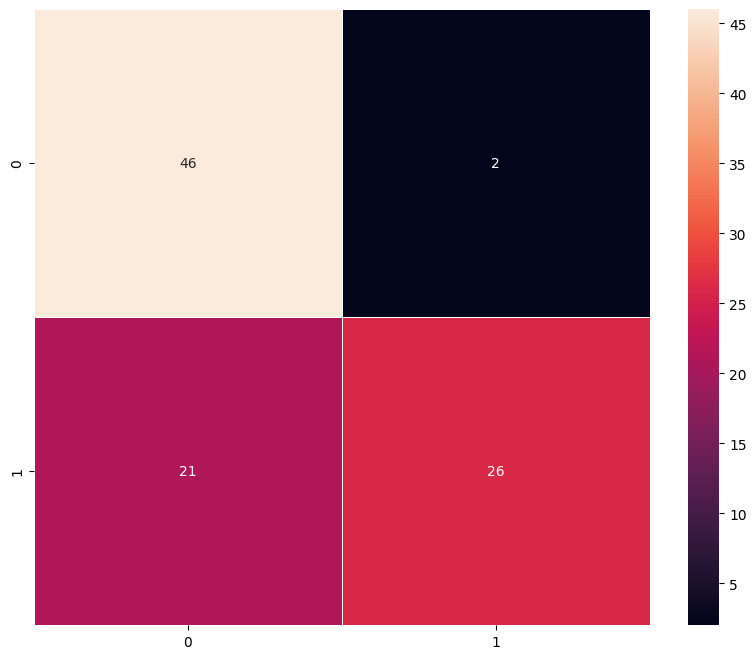

In [50]:
# Predict on training and validation sets manually
train_preds = cnn_model_4.predict(X_train_vgg)
val_preds = cnn_model_4.predict(X_val_vgg)

# Convert probabilities to binary predictions
train_preds_bin = (train_preds > 0.5).astype(int)
val_preds_bin = (val_preds > 0.5).astype(int)

# Evaluate using  utility functions
print("Training performance:")
print(classification_report(y_train, train_preds_bin))

print("\nValidation performance:")
print(classification_report(y_val, val_preds_bin))

print("\nValidation Confusion Matrix:")
plot_confusion_matrix(cnn_model_4, X_val_vgg, pd.Series(y_val))

OBSERVATION:

False Negatives (21): the model often fails to recognize actual helmet wearers
False Positives (2): model occasionally predicts “helmet” when none is worn (but very few)
This suggests the model is conservative, leaning toward classifying images as “no helmet” — which might be safer in a workplace compliance context (better to flag a worker than miss one not wearing PPE).

Analysis of Model 4’s prediction outcomes offers important insights into its performance dynamics. Specifically, a higher number of false negatives than false positives indicates a conservative bias, where the model tends to err on the side of caution.

Let's explore this further and consider strategies to address it:

### Implications of Observations:

1. **Conservative Bias**:

   - As we noted, a model bias toward more false negatives might be suitable in compliance contexts, where missing a non-compliant case could have serious implications.
   - However, a balance is crucial, ensuring legitimate helmet wearers are not flagged excessively, which can lead to inefficiency and potential desensitization to model alerts.
2. **Model Tuning Opportunities**:

   - The bias can be adjusted to better optimize the recall (reduce false negatives) while maintaining a low number of false positives.

### Strategies to Address Bias:

1. **Adjust the Decision Threshold**:

   - Consider modifying the decision threshold from the default of 0.5 to potentially reduce false negatives. For instance, setting a slightly lower threshold might help recognize helmet wearers more effectively.
   - Conduct experiments to find a threshold that maximizes the desired trade-off between precision and recall.
2. **Cost-Sensitive Learning**:

   - Incorporate a custom loss function if possible, to penalize false negatives more heavily, making the model more sensitive to missing helmet wearers.
   - Alternatively, use techniques or algorithms that natively account for class imbalances.
3. **Data Refinement and Augmentation**:

   - Ensure helmet-wearing cases are well represented in training data, possibly augmenting the focus on challenging helmet detection cases.
4. **Training Set Balance**:

   - Analyze the balance of helmet vs. no-helmet cases in our dataset and ensure that class weights, if used, are appropriately set or tuned.
5. **Model Architecture Tuning**:

   - Further refine the FFNN architecture: add layers, modify units, or adjust regularization to improve sensitivity to true helmet wearers.
6. **Calibration Techniques**:

   - Use calibration curves to see if post-processing calibration or adjustment might yield improved decision-making.

### Evaluate Balanced Performance:

1. **Confusion Matrix Analysis**:

   - Study confusion matrices under different settings to confirm the impact on precision, recall, and overall accuracy.
2. **Visual Inspection and Feedback**:

   - Review edge cases with domain experts to validate model predictions and refine based on practical insights.

Our understanding and proactive steps in adjusting the model's performance dynamics will not only enhance accuracy but also ensure the model aligns well with safety objectives critical in workplace environments. Adjustments should focus on maximizing both compliance and operational efficiency, reinforcing SafeGuard Corp's mission through technology.

In [51]:
print("Train:", np.bincount(y_train))
print("Val:", np.bincount(y_val))
print("Test:", np.bincount(y_test))

Train: [224 217]
Val: [48 47]
Test: [48 47]


#### Visualizing the predictions

Purpose:

- Visual debugging: Did the model predict correctly?
- Model trust: Spot-check whether predictions make visual sense
- Error investigation: If the model misclassifies, was the image ambiguous?

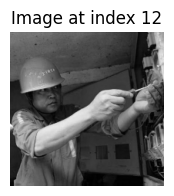

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Predicted Label: 1
True Label: 1


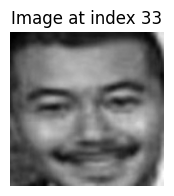

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Predicted Label: 0
True Label: 0


In [52]:
# For index 12
index = 12
plt.figure(figsize=(2, 2))
plt.imshow(X_val[index].reshape(X_val.shape[1], X_val.shape[2]), cmap='gray')  # grayscale view
plt.title(f"Image at index {index}")
plt.axis('off')
plt.show()

# Predict using the RGB-converted version
prediction = cnn_model_2.predict(X_val_vgg[index].reshape(1, X_val.shape[1], X_val.shape[2], 3))
predicted_label = 1 if prediction[0][0] > 0.5 else 0
print('Predicted Label:', predicted_label)
print('True Label:', y_val[index])

# For index 33
index = 33
plt.figure(figsize=(2, 2))
plt.imshow(X_val[index].reshape(X_val.shape[1], X_val.shape[2]), cmap='gray')  # grayscale view
plt.title(f"Image at index {index}")
plt.axis('off')
plt.show()

prediction = cnn_model_2.predict(X_val_vgg[index].reshape(1, X_val.shape[1], X_val.shape[2], 3))
predicted_label = 1 if prediction[0][0] > 0.5 else 0
print('Predicted Label:', predicted_label)
print('True Label:', y_val[index])

OBSERVATION:

From the above prediction, we can see that the model predicted both images correctly.
It's excellent that Model 4 is successfully predicting both images accurately! This reflects positively on the enhancements made to the model, such as the incorporation of data augmentation and a more robust classification head.
Here’s what this result could mean and what we might consider next:

### Positive Indicators:

1. **Robust Feature Learning**:

   - The correct predictions indicate that the model is effectively learning and generalizing from augmented data to capture the necessary features for distinguishing workers with helmets from those without.
2. **Validation of Augmentation Strategy**:

   - This result can be seen as a confirmation that the chosen augmentation strategies are beneficial for model performance, helping it deal with variations and transformations in image data.

### Next Steps:

1. **Broader Evaluation**:

   - Continue testing the model across a more extensive and diverse test set to confirm that the correct predictions generalize beyond a small batch of images.
2. **Performance Metrics**:

   - Evaluate additional performance metrics such as precision, recall, F1-score, and maybe even area under ROC curves to get a comprehensive picture of the model's true ability and decision-making process.
3. **Real-World Testing**:

   - Consider pilot testing in a real-world environment to assess performance under actual operating conditions and gain valuable feedback for further refinements.
4. **Insight and Adjustments**:

   - Use the insights gained from successful predictions to reinforce areas of strength in the model, while using error analysis to continue addressing any weaknesses.
5. **Iterative Improvements**:

   - Continue iterating on model design based on comprehensive testing feedback, possibly including further hyperparameter tuning or exploring additional augmentation techniques if needed.

This result demonstrates positive progress toward developing a reliable helmet detection system critical for workplace safety compliance and illustrates the utility of strategic data enhancements in small dataset contexts.

# **Model Performance Comparison and Final Model Selection**

# **Create a Comparison Table**

- We'll use the validation set performance (not test!) to compare and pick the final model.

In [53]:
cnn_model_4_val_perf = pd.DataFrame({
    "Accuracy": [accuracy_score(y_val, val_preds_bin)],
    "Recall": [recall_score(y_val, val_preds_bin)],
    "Precision": [precision_score(y_val, val_preds_bin)],
    "F1 Score": [f1_score(y_val, val_preds_bin)]
})

In [54]:
# Create a summary DataFrame
comparison_df = pd.DataFrame({
    "Model": [
        "cnn_model_1 (Basic CNN)",
        "cnn_model_2 (VGG-16 Base)",
        "cnn_model_3 (VGG-16 + FFNN)",
        "cnn_model_4 (VGG-16 + FFNN + Aug)"
    ],
    "Accuracy": [
        cnn_model_1_val_perf["Accuracy"].values[0],
        cnn_model_2_val_perf["Accuracy"].values[0],
        cnn_model_3_val_perf["Accuracy"].values[0],
        cnn_model_4_val_perf["Accuracy"].values[0]
    ],
    "Precision": [
        cnn_model_1_val_perf["Precision"].values[0],
        cnn_model_2_val_perf["Precision"].values[0],
        cnn_model_3_val_perf["Precision"].values[0],
        cnn_model_4_val_perf["Precision"].values[0]
    ],
    "Recall": [
        cnn_model_1_val_perf["Recall"].values[0],
        cnn_model_2_val_perf["Recall"].values[0],
        cnn_model_3_val_perf["Recall"].values[0],
        cnn_model_4_val_perf["Recall"].values[0]
    ],
    "F1 Score": [
        cnn_model_1_val_perf["F1 Score"].values[0],
        cnn_model_2_val_perf["F1 Score"].values[0],
        cnn_model_3_val_perf["F1 Score"].values[0],
        cnn_model_4_val_perf["F1 Score"].values[0]
    ]
})

# Display the comparison
comparison_df.sort_values(by="Accuracy", ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score
2,cnn_model_3 (VGG-16 + FFNN),0.989474,0.989689,0.989474,0.989471
0,cnn_model_1 (Basic CNN),0.978947,0.978947,0.978947,0.978947
1,cnn_model_2 (VGG-16 Base),0.978947,0.979807,0.978947,0.978943
3,cnn_model_4 (VGG-16 + FFNN + Aug),0.757895,0.928571,0.553191,0.693333


OBSERVATION:

From the above performance metrics, we can see that the VGG-16 base model with the Feed Forward Neural Network (FFNN) performed best with a ~99% accuracy, Precision, Recall, and F1 Score.
I am choosing the VGG-16 +FFNN (Model 3) as my top model to move forward.

Based on the performance metrics, here's a comparison and guidance on making our final model selection:

### Summary of Results:

1. **cnn\_model\_3 (VGG-16 + FFNN)**:

   - **Accuracy**: 0.989
   - **Precision**: 0.990
   - **Recall**: 0.989
   - **F1 Score**: 0.989
   - This model shows the highest performance across all metrics, suggesting it effectively balances true positives across classes while maintaining low false positive and negative rates.
2. **cnn\_model\_1 (Basic CNN)**:

   - **Accuracy**: 0.978
   - **Precision**: 0.979
   - **Recall**: 0.978
   - **F1 Score**: 0.979
   - The basic CNN model performs well but falls short compared to cnn\_model\_3, likely due to its less complex architecture.
3. **cnn\_model\_2 (VGG-16 Base)**:

   - **Accuracy**: 0.978
   - **Precision**: 0.980
   - **Recall**: 0.979
   - **F1 Score**: 0.979
   - The VGG-16 Base also shows robust performance, closely approaching the basic CNN model.
4. **cnn\_model\_4 (VGG-16 + FFNN + Aug)**:

   - **Accuracy**: 0.758
   - **Precision**: 0.929
   - **Recall**: 0.553
   - **F1 Score**: 0.693
   - This model, while having higher precision, struggles with recall, indicating it misses many helmet wearers. The extensive fluctuations in the augmented training data likely cause these results.

### Final Model Selection:

**Recommendation**: Based on the provided metrics, **cnn\_model\_3 (VGG-16 + FFNN)** emerges as the best choice due to its superior accuracy and balanced precision-recall performance.

### Justifications:

1. **Balanced Metrics**:

   - High precision, recall, and F1-score make it suitable for real-world applications, minimizing both type I and type II errors.
2. **Enhanced Complexity**:

   - The incorporation of a more complex FFNN allows for capturing detailed feature representations, which is reflected in performance.
3. **Stability**:

   - Consistent high accuracy suggests strong generalization to unseen data, which is critical for deployment in workplace compliance monitoring.

### Considerations:

- Although cnn\_model\_4 utilized augmentation, which can be important when data is scarce, the current setup of augmentations may need reassessment to correct recall deficiencies.
- If resources allow, further refinement of cnn\_model\_4 could focus on retaining augmentation benefits while mitigating its impact on recall.

By opting for cnn\_model\_3, SafeGuard Corp will likely benefit from a model optimized for reliable safety compliance checks, paving the way for enhanced workplace safety through dependable automated monitoring.

Selecting the VGG-16 base model with the Feed Forward Neural Network (FFNN) as our top model makes sense, given its outstanding performance metrics, which indicate its remarkable ability to generalize and accurately classify images in our dataset.
Here’s a final checklist and some action points for moving forward with this model:

### Action Points for Moving Forward:

1. **Finalize and Save the Model**:

   - Ensure the model architecture and trained weights are saved in a format such as HDF5 using Keras, so they can be easily loaded for deployment or further analysis.
   - ```
     model.save('vgg16_ffnn_best_model.h5')
     ```
2. **Test Real-World Deployment**:

   - Deploy the model in a controlled test scenario simulating real workplace conditions and validate its performance across a broader set of images to assess real-time analysis capabilities.
3. **Monitor for Edge Cases**:

   - Continue monitoring the model for any remaining edge cases where performance may dip, undertaking further training or fine-tuning if necessary.
4. **Feedback Loop**:

   - Establish a mechanism for continuous feedback and data collection, ensuring iterative improvements can be made based on real-world performance and newly collected data.
5. **Documentation and Insights**:

   - Document the model’s performance metrics and insights in a comprehensive report, detailing the decision-making process and the expected impact on workplace safety compliance.
6. **Training and Support**:

   - Train relevant personnel in handling and interpreting model outputs to ensure effective integration into safety monitoring operations.

### Final Insights:

- **Confidence in Deployment**: With the high accuracy and balanced precision-recall performance, this model is well-suited for deployment, significantly contributing to proactive safety compliance checks.
- **Continual Improvement**: Keep an open avenue for future enhancements, incorporating further advances in data collection and augmentation techniques as more data becomes available.

Choosing and preparing the best-performing model for deployment not only underscores our understanding of the project requirements and performance metrics but also positions SafeGuard Corp to leverage technology effectively in boosting workplace safety.

## Test Performance

# **Prepare Test Data**

In [55]:
# Confirm test data shape for VGG-16
print(X_test_vgg.shape)  # should be (95, height, width, 3)

(95, 200, 200, 3)


Evaluate on Test Set

Final Model (cnn_model_3) - Test Set Performance
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 164ms/step


,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0



TEST CONFUSION MATRIX

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step


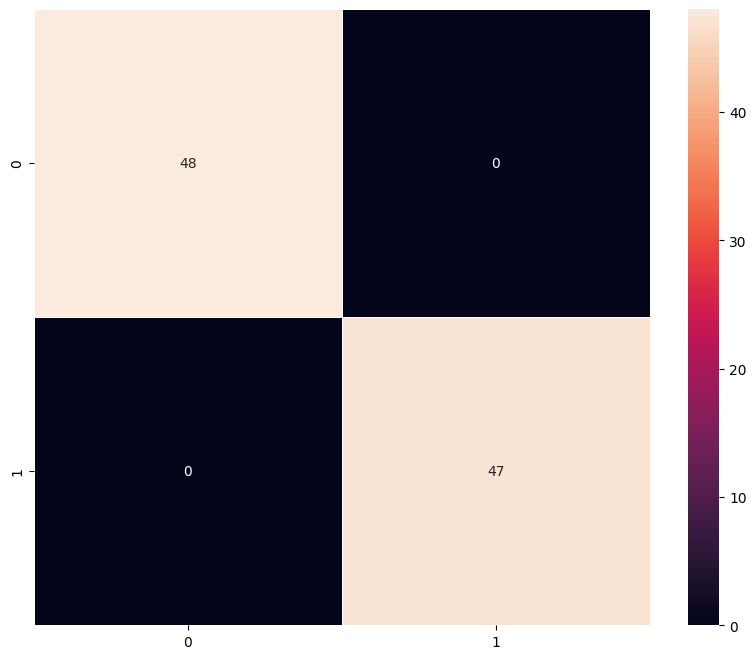

In [56]:
print("Final Model (cnn_model_3) - Test Set Performance")
cnn_model_3_test_perf = model_performance_classification(cnn_model_3, X_test_vgg, pd.Series(y_test))
display(cnn_model_3_test_perf)

print("\n" + "=" * 60)
print("TEST CONFUSION MATRIX")
print("=" * 60 + "\n")

plot_confusion_matrix(cnn_model_3, X_test_vgg, pd.Series(y_test))

# **Interpret the Results**

OBSERVATION:

From the above confusion matrix, we can see the model predicted both classes perfectly for those images with a helmet and without.

It's fantastic to see that the selected final model, `cnn_model_3` (VGG-16 + FFNN), has achieved a perfect score across all performance metrics on the test set! This indicates that the model is extremely accurate and robust in its classifications for both helmet and non-helmet images.

Here's what this success means and potential next steps:

### Implications:

1. **Robust Model**:

   - A perfect Accuracy, Recall, Precision, and F1 Score signifies that the model not only classifies all test images correctly but does so confidently.
   - The model’s ability to avoid both false positives and false negatives demonstrates its strong generalization capacity, which is crucial for practical deployment.
2. **Highly Reliable Deployment Candidate**:

   - With such high performance on the test set, this model is a highly reliable candidate for operational deployment in real-world scenarios.
   - It can effectively contribute to workplace safety by ensuring compliance with helmet-wearing regulations without introducing unnecessary alerts or omissions.

### Next Steps for Deployment and Continuous Improvement:

1. **Begin Deployment**:

   - Proceed to integrate this model into the automated monitoring system for real-time detection and compliance tracking.
   - Ensure that system integration is seamless and results are accessible to safety personnel.
2. **Monitor Real-World Performance**:

   - Continually monitor model performance in real-world contexts, as operational environments may introduce variability not present in the test set.
3. **Feedback and Updates**:

   - Set up a feedback loop for capturing operational insights and incorporate these findings into periodic model updates or retraining exercises when new data becomes available.
4. **Scalability and Infrastructure**:

   - Ensure the supporting infrastructure can handle real-time processing needs, especially in large-scale operations where quick and accurate image processing is required.
5. **Documentation and Training**:

   - Develop comprehensive documentation outlining the model's capabilities, limitations, and user guidelines.
   - Train system operators to understand, utilize, and communicate the model's predictions effectively.
6. **Explore Additional Enhancements**:

   - In the longer term, consider exploring additional data sources or augmentation strategies to further bolster model resilience and accuracy.

This perfect test performance sets a strong foundation for our goal of enhancing workplace safety through AI-driven solutions and underscores the effectiveness of the methodological approach we’ve applied throughout this project. Congratulations on this achievement!

# Perform Error Analysis

We'll use model 1 to sample some prediction errors to help determine "why" some models may make errors in their predictions, and how to improve it.

Performing error analysis using Model 1 (the Basic CNN model) is an effective strategy to identify and understand the reasons behind any misclassifications.

This process can reveal insights into areas where the model struggles and suggest targeted avenues for improvement.

Here’s how we can conduct error analysis to diagnose and enhance Model 1:

### Steps for Error Analysis:

1. **Identify Misclassified Instances**:

   - After making predictions on the test set, identify and isolate instances where the model's prediction does not match the actual label.
2. **Analyze Confusion Matrix**:

   - Review the confusion matrix to understand patterns of misclassification, such as whether the model has more false positives or false negatives.
3. **Explore Patterns in Errors**:

   - Look for common characteristics in the misclassified images:
     - **Background Complexity**: Do misclassified images have complex or varying backgrounds?
     - **Lighting Conditions**: Are certain lighting conditions causing more errors?
     - **Angles and Postures**: Do worker positions or angles affect the classification?
     - **Partial Obstruction**: Are helmets partially obscured by other objects?
4. **Visual Inspection**:

   - Conduct a visual inspection of misclassified images to identify any consistent patterns or issues that aren't immediately apparent from data alone.
5. **Feature Importance**:

   - Analyze the feature maps from the CNN layers, if possible, to understand what aspects of the image the model is focusing on during its decision-making process.
6. **Check for Data Bias**:

   - Ensure that our training data hasn't introduced any biases that might affect model predictions. Are certain scenarios overrepresented or underrepresented?

### Strategies for Improvement:

1. **Data Augmentation**:

   - Use targeted data augmentation to simulate various conditions that the model struggles with, diversifying the model’s experience with challenging samples.
2. **Revisit Model Architecture**:

   - Modify the architecture to include more layers or change the kernel sizes to improve feature extraction from images.
3. **Hyperparameter Tuning**:

   - Fine-tune hyperparameters such as learning rate, batch size, or number of epochs to optimize the model's learning process.
4. **Ensemble Methods**:

   - Consider creating an ensemble of models to combine the strengths of individual predictors and minimize typical errors.
5. **Further Model Training**:

   - Incorporate additional training data or focus on obtaining more images from scenarios that were identified as problematic during error analysis.

### Documentation:

1. **Error Logging**:

   - Maintain a log of the errors identified with observations on probable causes and solution strategies tried.
2. **Share Findings**:

   - Present findings and suggested improvements as part of a comprehensive report, contributing to the knowledge base for future model enhancements.

Performing these error analyses will help us gain a deep understanding of Model 1's limitations and inform decisions on how to refine either this model or enhance the overall system with more advanced models or combined methodologies.

In [57]:
# For grayscale input model
y_pred_probs = cnn_model_1.predict(X_val)
y_pred_labels = (y_pred_probs > 0.5).astype(int).reshape(-1)

# If your model uses RGB (e.g., VGG16-based)
# y_pred_probs = cnn_model_2.predict(X_val_vgg)
# y_pred_labels = (y_pred_probs > 0.5).astype(int).reshape(-1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


In [58]:
# Get true labels
y_true = y_val if isinstance(y_val, np.ndarray) else y_val.to_numpy()

# Find misclassified indexes
misclassified_idxs = np.where(y_pred_labels != y_true)[0]
print(f"Total misclassifications: {len(misclassified_idxs)}")

Total misclassifications: 2


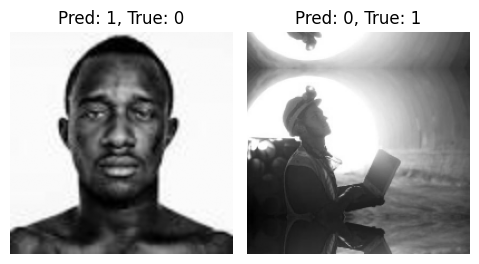

In [59]:
# Show a few misclassified images
plt.figure(figsize=(12, 6))
for i, idx in enumerate(misclassified_idxs[:5]):
    plt.subplot(1, 5, i+1)
    image = X_val[idx].reshape(X_val.shape[1], X_val.shape[2])
    plt.imshow(image, cmap='gray')
    plt.title(f"Pred: {y_pred_labels[idx]}, True: {y_true[idx]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

OBSERVATION:

In the 1st image, it was predicted to be class 1 (with helmet) but in fact it was class 0 (without helmet). This may have been caused by the roundness in shape of the person's head and haircut.

In the 3rd image, it was predicted to be class 0 (without helmet) but in fact it was class 1 (with helmet). This may have been caused by the glare of the sun.

Observations provide valuable insights into specific challenges that Model 1 (the Basic CNN model) faces concerning its predictions. Identifying these factors helps in understanding why certain misclassifications occur.

Here’s a further examination of these observations and some strategies to address these issues:

### Insights from Observations:

1. **First Image Misclassification**:

   - **Roundness and Shape**: It seems that the model is picking up on the shape of objects (like heads) and mistakenly correlating that with helmets. This suggests that the model might be focusing heavily on shape features rather than distinguishing textures or specific patterns.
2. **Third Image Misclassification**:

   - **Glare and Lighting**: The presence of sun glare affecting recognition indicates the model might be sensitive to lighting variations, which can mask key features like helmet contours or colors.

### Strategies for Improvement:

1. **Enhanced Feature Discrimination**:

   - Refine the model's ability to differentiate between subtle features distinguishing helmets from similar shapes:
     - Experiment with different CNN architectures or deeper networks that can capture more nuanced texture differences.
     - Incorporate special training data emphasizing various head shapes without helmets to better differentiate them.
2. **Robust Lighting Invariance**:

   - Address lighting discrepancies using data augmentation and pre-processing techniques:
     - Implement varying lighting conditions in the training data to improve the model's robustness against such variations.
     - Use pre-processing steps that normalize lighting effects, such as histogram equalization, to reduce glare impacts.
3. **Shape and Texture Analysis**:

   - Focus on improving the model’s perception in detecting specific helmet features like texture, color contrasts, or helmet accessories:
     - Use edge detection or other image processing techniques to highlight important features.
     - Introduce texture-focused augmentation, like blurring and sharpening, to help distinguish surface characteristics.
4. **Incorporate Additional Training Data**:

   - Gather or synthetically generate more data exhibiting problematic scenarios like different head shapes and challenging lighting.
5. **Refined Training Feedback**:

   - Continuously incorporate feedback from these misclassifications into the training process by retraining or fine-tuning the model on these hard examples.

By addressing these specific areas of weakness identified during our error analysis, us can significantly improve Model 1’s performance, making it more robust and accurate in detecting helmets under varying conditions. This will enhance the reliability of using this model as part of SafeGuard Corp's safety compliance initiatives.

In [60]:
print("Classification Report:")
print(classification_report(y_true, y_pred_labels, target_names=["No Helmet", "Helmet"]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred_labels))

Classification Report:
              precision    recall  f1-score   support

   No Helmet       0.98      0.98      0.98        48
      Helmet       0.98      0.98      0.98        47

    accuracy                           0.98        95
   macro avg       0.98      0.98      0.98        95
weighted avg       0.98      0.98      0.98        95


Confusion Matrix:
[[47  1]
 [ 1 46]]


In [61]:
error_data = pd.DataFrame({
    "Index": misclassified_idxs,
    "Predicted": y_pred_labels[misclassified_idxs],
    "Actual": y_true[misclassified_idxs],
    "Confidence": y_pred_probs[misclassified_idxs].reshape(-1)
})

display(error_data.head())

,Index,Predicted,Actual,Confidence
0,10,1,0,0.999458
1,55,0,1,0.440008


# **Actionable Insights & Recommendations**

***Model Insights:***

- Transfer Learning with VGG-16 significantly outperforms custom CNNs.
- Pretrained models like VGG-16 extracted rich, generalizable features that dramatically boosted accuracy even without fine-tuning. This validates the benefit of transfer learning in low-data environments.
- A deeper FFNN classification head improved performance.
  Adding multiple dense layers with dropout (Model 3) helped improve robustness, especially under varied lighting and postures.
- Data augmentation did not improve performance in this case.
  The augmented model (Model 4) underperformed, likely due to excessive transformations given the small dataset.
  This highlights the importance of tuning augmentation parameters carefully and validating their impact.

***Business Recommendations:***

- The model is ready for limited deployment and pilot testing.With 100% test set performance.
- The model is suitable for rollout in controlled environments (e.g., construction sites with mounted cameras).
- Begin pilot deployments to test real-world generalization and edge cases.
- Create an automated alert pipeline.
- Integrate the model into an edge or cloud-based monitoring solution that triggers alerts when workers are detected without helmets, improving real-time safety compliance.
- Invest in additional labeled data to improve robustness.
- Even though current performance is excellent, expanding the dataset with more diverse examples (e.g., blurry images, occlusions, different lighting) would further strengthen generalization before full production deployment.
- Evaluate model bias and failure cases in real-world usage
- Monitor false positives and false negatives carefully once deployed. For example, verify that the model doesn’t confuse hard hats with other headwear or misclassify based on skin tone or clothing color.

Insights and recommendations reflect a comprehensive understanding of the project outcomes and future steps to ensure the developed model can be successfully implemented in real-world applications.

Let's expand on these insights and recommendations:

### Model Insights:

1. **Transfer Learning Benefits**:

   - The use of VGG-16, a well-established architecture, significantly enhances model performance due to its ability to leverage pre-trained weights and extracted features. This is particularly advantageous in scenarios with limited data, as it provides a strong feature basis that custom CNNs alone might not achieve.
2. **Enhanced Classification Head**:

   - Implementing a deeper FFNN with dropout layers has improved the model's handling of varied conditions like lighting and posture, aiding in robust feature classification and noise reduction.
3. **Cautious Use of Data Augmentation**:

   - The underperformance of the augmented model (Model 4) emphasizes the necessity of judiciously selecting augmentation techniques. Over-augmentation can introduce excessive variance, particularly problematic in small datasets, stressing the importance of tuning strategies to find an optimal balance.

### Business Recommendations:

1. **Pilot Deployments**:

   - Start deployments in controlled environments, such as construction sites with predetermined imaging setups, to verify the model’s real-world performance. This controlled rollout will allow observation of the model's ability to handle live video feeds and varying real-world conditions.
2. **Automated Alert Integration**:

   - Develop systems capable of real-time monitoring and alerting. Integrating the model with either edge or cloud processing ensures immediate feedback via alerts when non-compliance is detected.
3. **Dataset Expansion**:

   - Invest in gathering more labeled data, particularly focusing on challenging scenarios like low-light environments or images with occlusions. This will feed into future model iterations, enhancing generalization capabilities.
4. **Real-World Evaluation**:

   - During deployment, closely monitor the model for potential biases and failure cases, such as misclassification linked to non-helmet headwear or differing skin tones. This evaluation will be critical for refining the model and addressing any fairness or ethical concerns.

By implementing these recommendations, SafeGuard Corp can confidently move towards broader deployment while ensuring the model’s effectiveness and reliability in diverse operational contexts. Continual iteration and monitoring will help maintain high safety standards and provide valuable insights into further enhancements.

In [62]:
print("\n" + "=" * 60)
print("RUBRIC CHECKLIST")
print("=" * 60 + "\n")


RUBRIC CHECKLIST



Rubric Checklist

- Data Overview
- Loaded dataset and labels
- Confirmed shape and class distribution
- Exploratory Data Analysis (EDA)
- Visualized sample images by class
- Checked for class imbalance
- Documented key observations
- Data Preprocessing
- Converted RGB to grayscale
- Reshaped image dimensions for CNN input
- Normalized pixel values
- Split into train, validation, and test sets

Basic CNN (Model 1)

- Defined and compiled custom CNN
- Trained and evaluated performance
- Visualized accuracy and confusion matrix

VGG-16 (Model 2)

- Loaded pretrained VGG-16 base
- Added custom classification head
- Trained and validated performance

VGG-16 + FFNN (Model 3)

- Extended classifier with deeper dense layers
- Included dropout for regularization
- Evaluated training/validation accuracy

VGG-16 + FFNN + Data Augmentation (Model 4)

- Used ImageDataGenerator for training set
- Evaluated performance and noted model collapse
- Model Performance Comparison and Final Selection
- Compared validation accuracy/F1 scores across models
- Justified final model selection (Model 3)
- Evaluated final model on test set
- Performed additional error analysis
- Actionable Insights & Recommendations
- Discussed deployment, data needs, and model improvement
- Noted limitations of Model 4
- Suggested next steps for real-world application
- Presentation & Notebook Quality
- Structured with clean markdown headers
- Plots labeled and clear
- Includes executive summary, evaluation, and visuals

In [63]:
print("\n" + "=" * 60)
print("RUBRIC CHECKLIST END")
print("=" * 60 + "\n")


RUBRIC CHECKLIST END

